# Visualisasi dan Deteksi Anomali Jumlah Pemain Harian Game Steam dengan Image Encoding dan CNN

Notebook ini adalah versi lengkap tugas visualisasi time series dengan CNN. Metodenya mengikuti Rahadian dkk. (2023): potongan time series diubah menjadi gambar dengan beberapa jenis image encoding, lalu CNN belajar membedakan gambar dari data normal dan data yang mengandung anomali.

Datanya adalah jumlah pemain bersamaan harian enam game Steam (sumber SteamDB, lewat repositori GitHub `ibrhr/Steam-Game-Analytics`). Alurnya:

1. Data dan EDA: membaca, membersihkan, dan melihat pola data.
2. Segmentasi dan suntikan anomali: memotong data menjadi segmen 20 hari dan membuat versi anomalinya.
3. Image encoding: mengubah setiap segmen menjadi gambar dengan 14 encoding dan menghitung statistik matriksnya.
4. Training CNN: melatih satu CNN untuk tiap encoding.
5. Korelasi Pearson: menghubungkan statistik matriks dengan akurasi CNN.
6. Grad-CAM: melihat bagian gambar (dan hari) yang diperhatikan CNN.
7. Ringkasan insight.

Notebook dijalankan dari atas ke bawah. Semua figur disimpan ke `figures/` dan semua tabel ke `results/`.

## Konfigurasi

Saklar `LATIH_ULANG` menentukan apa yang terjadi di bagian 4:

- `False` (bawaan): CNN tidak dilatih ulang. Bobot model dimuat dari folder `models/` dan hasil training dibaca dari `results/`, sehingga semua angka sama dengan yang ada di paper. Mode ini cukup beberapa menit.
- `True`: ke-14 CNN dilatih ulang dari awal (sekitar 10 sampai 15 menit). Training memakai GPU Apple (MPS) yang tidak menjamin hasil identik, sehingga akurasi bisa sedikit berbeda dari paper walaupun seed-nya sama. Bobot di `models/` dan tabel hasil di `results/` akan ditimpa.

Waktu komputasi (encoding dan training) juga hanya disimpan ulang ke `results/` jika `LATIH_ULANG = True`, karena waktu selalu sedikit berbeda setiap kali dijalankan.

In [1]:
LATIH_ULANG = False

import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from pyts.image import GramianAngularField, MarkovTransitionField

warnings.filterwarnings('ignore')
SEED = 42
SEG_LEN = 20          # panjang segmen (hari)
MAX_GAP = 3           # celah tanggal paling lama yang diisi interpolasi
BUMP_RATIO = 1.5      # batas lonjakan asli: maksimum > 1,5 x median segmen
IMG, BATCH, EPOCHS, LR = 150, 20, 20, 1e-3
DEV = 'mps' if torch.backends.mps.is_available() else 'cpu'

ROOT = Path('..')
RAW, PROC, FIG, RES, MODELS = ROOT/'data/raw', ROOT/'data/processed', ROOT/'figures', ROOT/'results', ROOT/'models'
for p in (PROC, FIG, RES, MODELS):
    p.mkdir(parents=True, exist_ok=True)

NAMES = {'dark_souls_3': 'Dark Souls 3', 'ets2': 'Euro Truck Simulator 2', 'garrys_mod': "Garry's Mod",
         'rainbow_six_siege': 'Rainbow Six Siege', 'stardew_valley': 'Stardew Valley', 'terraria': 'Terraria'}
GAMES = list(NAMES)
START_OVERRIDE = {'garrys_mod': '2012-01-01'}
T_MULAI = time.perf_counter()
print('LATIH_ULANG =', LATIH_ULANG, '| perangkat:', DEV)

LATIH_ULANG = False | perangkat: mps


# 1. Data dan EDA

## 1.1 Membaca dan membersihkan data

Setiap game punya satu file CSV berisi jumlah pemain bersamaan. Aturan pembersihannya:

1. Data diseragamkan ke harian dengan nilai maksimum per hari, karena sekitar satu bulan terakhir di file tersedia per jam dan per 10 menit.
2. Hari terakhir (2025-06-21) dibuang karena datanya belum lengkap.
3. Data dimulai dari hari pertama dengan minimal 1.000 pemain, untuk membuang nilai 1 sampai 3 sebelum game rilis. Garry's Mod dimulai 2012-01-01 karena data sebelumnya banyak yang bolong.
4. Tanggal kosong hanya diisi interpolasi linear kalau celahnya paling lama 3 hari.

Tabel di bawah menunjukkan rentang tanggal, jumlah hari, dan jumlah hari yang hilang untuk tiap game.

In [2]:
def load_daily(game):
    d = pd.read_csv(RAW/f'{game}_player_counts.csv', encoding='utf-8-sig', parse_dates=['DateTime'])
    s = d.set_index('DateTime')['Players'].sort_index().resample('D').max()
    return s.iloc[:-1]

def fill_short_gaps(s, max_gap=MAX_GAP):
    isna = s.isna()
    run_id = (isna != isna.shift(fill_value=False)).cumsum()
    run_len = isna.groupby(run_id).transform('sum')
    interp = s.interpolate(limit_area='inside')
    fill = isna & (run_len <= max_gap)
    out = s.copy()
    out[fill] = interp[fill]
    return out, fill

daily, filled, info = {}, {}, []
for g in GAMES:
    s = load_daily(g)
    start = pd.Timestamp(START_OVERRIDE[g]) if g in START_OVERRIDE else s[s >= 1000].index[0]
    s = s[s.index >= start]
    n_missing = int(s.isna().sum())
    s, fill = fill_short_gaps(s)
    daily[g], filled[g] = s, fill
    info.append(dict(game=NAMES[g], mulai=start.date(), akhir=s.index[-1].date(), jumlah_hari=len(s),
                     hari_hilang=n_missing, diisi_interpolasi=int(fill.sum()),
                     tetap_kosong=int(s.isna().sum()), median_pemain=int(s.median())))
info = pd.DataFrame(info)
info

,game,mulai,akhir,jumlah_hari,hari_hilang,diisi_interpolasi,tetap_kosong,median_pemain
0,Dark Souls 3,2016-04-12,2025-06-20,3357,0,0,0,9546
1,Euro Truck Simulator 2,2013-01-01,2025-06-20,4554,110,1,109,29242
2,Garry's Mod,2012-01-01,2025-06-20,4920,25,4,21,35501
3,Rainbow Six Siege,2015-12-01,2025-06-20,3490,0,0,0,71573
4,Stardew Valley,2016-02-26,2025-06-20,3403,0,0,0,27131
5,Terraria,2011-05-15,2025-06-20,5151,52,1,51,26767


## 1.2 Jumlah pemain per game

Grafik pertama memperlihatkan tren jangka panjang dan lonjakan tiap game. Grafik kedua menumpuk semua game dengan sumbu log, sehingga terlihat bahwa skala tiap game sangat berbeda. Karena itu data nanti distandarisasi per game.

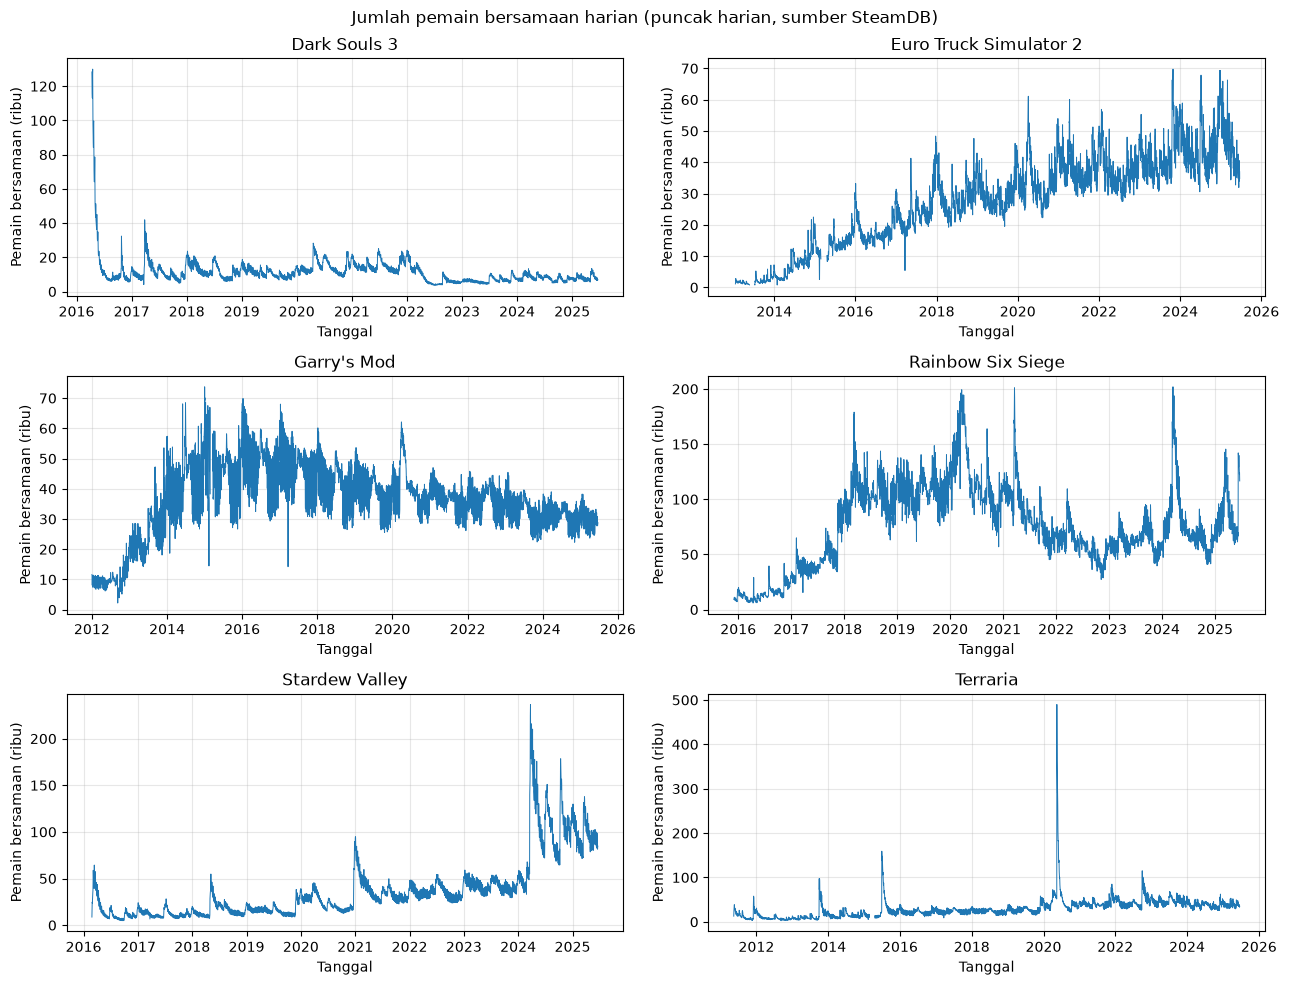

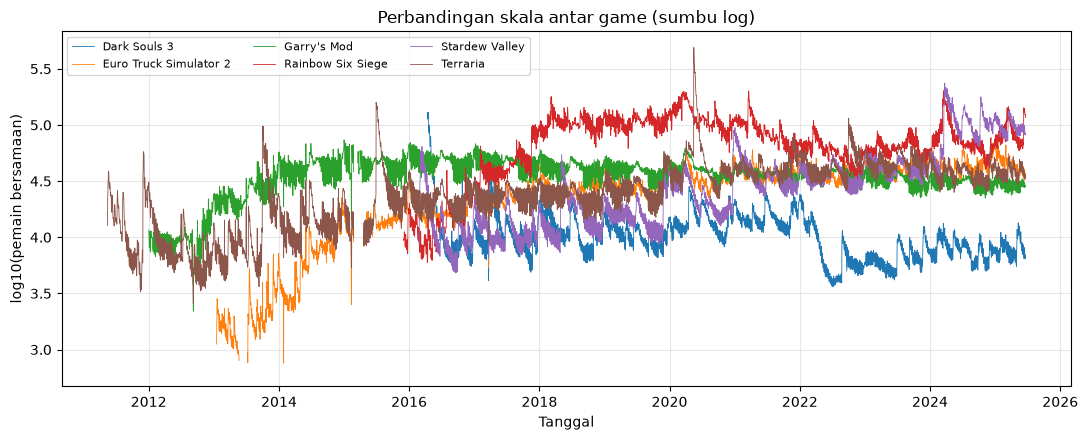

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(13, 10))
for ax, g in zip(axes.ravel(), GAMES):
    s = daily[g]
    ax.plot(s.index, s.values / 1000, lw=0.7)
    ax.set_title(NAMES[g]); ax.set_xlabel('Tanggal'); ax.set_ylabel('Pemain bersamaan (ribu)'); ax.grid(alpha=0.3)
fig.suptitle('Jumlah pemain bersamaan harian (puncak harian, sumber SteamDB)')
fig.tight_layout(); fig.savefig(FIG/'01_pemain_harian.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
for g in GAMES:
    ax.plot(daily[g].index, np.log10(daily[g].values), lw=0.6, label=NAMES[g])
ax.set_xlabel('Tanggal'); ax.set_ylabel('log10(pemain bersamaan)'); ax.grid(alpha=0.3); ax.legend(ncol=3, fontsize=8)
ax.set_title('Perbandingan skala antar game (sumbu log)')
fig.tight_layout(); fig.savefig(FIG/'02_skala_antar_game.png', dpi=150); plt.show()

## 1.3 Pola mingguan

Supaya tren jangka panjang tidak ikut terhitung, jumlah pemain setiap hari dibagi dengan rata-rata 7 hari di sekitarnya. Nilai 1,0 berarti sama dengan rata-rata minggu itu, dan nilai 1,13 berarti 13% lebih ramai. Hasilnya dirata-ratakan per hari dalam seminggu. Hari mengikuti zona waktu data SteamDB (UTC).

Cara membaca: garis hitam putus-putus adalah rata-rata keenam game. Sabtu dan Minggu berada paling atas di semua game.

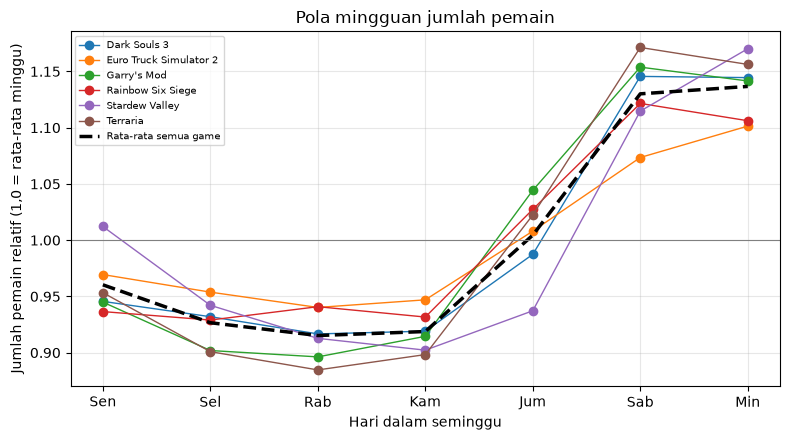

,Dark Souls 3,Euro Truck Simulator 2,Garry's Mod,Rainbow Six Siege,Stardew Valley,Terraria,Rata-rata semua game
Sen,0.946,0.969,0.945,0.937,1.012,0.953,0.960
Sel,0.932,0.954,0.902,0.929,0.942,0.901,0.927
Rab,0.917,0.940,0.896,0.941,0.913,0.885,0.915
Kam,0.919,0.947,0.915,0.932,0.902,0.898,0.919
Jum,0.987,1.008,1.044,1.027,0.937,1.022,1.004
Sab,1.146,1.073,1.154,1.122,1.115,1.171,1.130
Min,1.145,1.101,1.142,1.106,1.170,1.156,1.137


In [4]:
HARI = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
weekly = {}
for g in GAMES:
    s = daily[g]
    rel = s / s.rolling(7, center=True, min_periods=7).mean()
    weekly[NAMES[g]] = rel.groupby(rel.index.to_series().dt.day_of_week).mean()
weekly = pd.DataFrame(weekly)
weekly.index = HARI
weekly['Rata-rata semua game'] = weekly.mean(axis=1)
weekly.round(3).to_csv(RES/'pola_mingguan.csv')

fig, ax = plt.subplots(figsize=(8, 4.5))
for c in weekly.columns[:-1]:
    ax.plot(HARI, weekly[c], marker='o', lw=1, label=c)
ax.plot(HARI, weekly['Rata-rata semua game'], 'k--', lw=2.5, label='Rata-rata semua game')
ax.axhline(1, color='gray', lw=0.8)
ax.set_xlabel('Hari dalam seminggu'); ax.set_ylabel('Jumlah pemain relatif (1,0 = rata-rata minggu)')
ax.set_title('Pola mingguan jumlah pemain'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG/'03_pola_mingguan.png', dpi=150); plt.show()
weekly.round(3)

# 2. Segmentasi dan Suntikan Anomali

## 2.1 Memotong data menjadi segmen 20 hari

Setiap game dipotong menjadi segmen 20 hari berurutan yang tidak saling tumpang tindih, sama seperti panjang segmen di paper acuan. Segmen yang masih mengandung tanggal kosong dilewati.

Untuk tiap segmen juga dicatat apakah sudah ada lonjakan asli di dalamnya (nilai tertinggi lebih dari 1,5 kali median segmen). Segmen seperti ini tetap dianggap normal, dan persentasenya dibahas di bagian insight.

In [5]:
seg_raw, game_id, start_date, n_filled = [], [], [], []
for gi, g in enumerate(GAMES):
    s, fill = daily[g], filled[g]
    v, ok = s.values, ~s.isna().values
    i = 0
    while i + SEG_LEN <= len(v):
        if ok[i:i+SEG_LEN].all():
            seg_raw.append(v[i:i+SEG_LEN]); game_id.append(gi)
            start_date.append(s.index[i].date()); n_filled.append(int(fill.values[i:i+SEG_LEN].sum()))
            i += SEG_LEN
        else:
            i += 1
seg_raw = np.array(seg_raw, dtype=float); game_id = np.array(game_id)
N = len(seg_raw)
bump = seg_raw.max(axis=1) / np.median(seg_raw, axis=1) > BUMP_RATIO
print('Jumlah segmen normal:', N)

Jumlah segmen normal: 1229


## 2.2 Membagi data train, validasi, dan test

Satu segmen normal dan salinan anomalinya dihitung sebagai satu pasangan. Pembagian dilakukan per pasangan (70% train, 15% validasi, 15% test, seed tetap, proporsi tiap game dijaga), sehingga sepasang segmen selalu berada di bagian yang sama dan tidak ada kebocoran data antara train dan test.

In [6]:
idx_seg = np.arange(N)
tr, tmp = train_test_split(idx_seg, test_size=0.30, random_state=SEED, stratify=game_id)
va, te = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=game_id[tmp])
split = np.empty(N, dtype='<U5')
split[tr], split[va], split[te] = 'train', 'val', 'test'
split_tbl = pd.crosstab(pd.Series([NAMES[GAMES[i]] for i in game_id], name='game'), pd.Series(split, name='split'))[['train', 'val', 'test']]
split_tbl.to_csv(RES/'ringkasan_split.csv')
split_tbl

split,train,val,test
game,,,
Dark Souls 3,117,25,25
Euro Truck Simulator 2,154,33,33
Garry's Mod,171,36,37
Rainbow Six Siege,122,26,26
Stardew Valley,119,26,25
Terraria,177,38,39


## 2.3 Menyuntikkan anomali

Data asli tidak punya label anomali, jadi anomali dibuat seperti di paper acuan. Untuk setiap segmen normal dibuat satu salinan. Pada 1 sampai 5 hari yang dipilih acak, jumlah pemain dikalikan 2 sampai 5 (lonjakan) atau dibagi 2 sampai 5 (penurunan), dengan arah acak untuk tiap hari. Suntikan dilakukan pada jumlah pemain asli, sehingga artinya tetap "berlipat ganda".

In [7]:
rng = np.random.default_rng(SEED)
anom_raw = seg_raw.copy()
mask = np.zeros(seg_raw.shape, dtype=bool)
factor = np.ones(seg_raw.shape)
for i in range(N):
    k = rng.integers(1, 6)
    pos = rng.choice(SEG_LEN, size=k, replace=False)
    f = rng.uniform(2, 5, size=k)
    f = np.where(rng.random(k) < 0.5, f, 1 / f)
    anom_raw[i, pos] = seg_raw[i, pos] * f
    mask[i, pos], factor[i, pos] = True, f
k_anom = mask.sum(axis=1)
print('Titik anomali per segmen: rata-rata', k_anom.mean().round(2), '| lonjakan:', int((factor[mask] > 1).sum()), '| penurunan:', int((factor[mask] < 1).sum()))

Titik anomali per segmen: rata-rata 2.97 | lonjakan: 1825 | penurunan: 1829


## 2.4 Transformasi log10 dan standarisasi per game

Karena skala tiap game sangat berbeda, data diubah ke log10 lalu distandarisasi (rata-rata 0, SD 1) per game. Rata-rata dan SD hanya dihitung dari segmen normal di data train.

In [8]:
log_n, log_a = np.log10(seg_raw), np.log10(anom_raw)
mu = np.array([log_n[(game_id == gi) & (split == 'train')].mean() for gi in range(len(GAMES))])
sd = np.array([log_n[(game_id == gi) & (split == 'train')].std() for gi in range(len(GAMES))])
z_norm = (log_n - mu[game_id][:, None]) / sd[game_id][:, None]
z_anom = (log_a - mu[game_id][:, None]) / sd[game_id][:, None]
pd.DataFrame({'game': [NAMES[g] for g in GAMES], 'rata2_log10': mu.round(3), 'sd_log10': sd.round(3)}).to_csv(RES/'normalisasi_per_game.csv', index=False)

## 2.5 Contoh pasangan segmen

Kiri: jumlah pemain asli. Kanan: setelah log10 dan standarisasi, yaitu data yang masuk ke proses encoding. Garis normal dan anomali saling menimpa kecuali di hari yang disuntik (lingkaran merah).

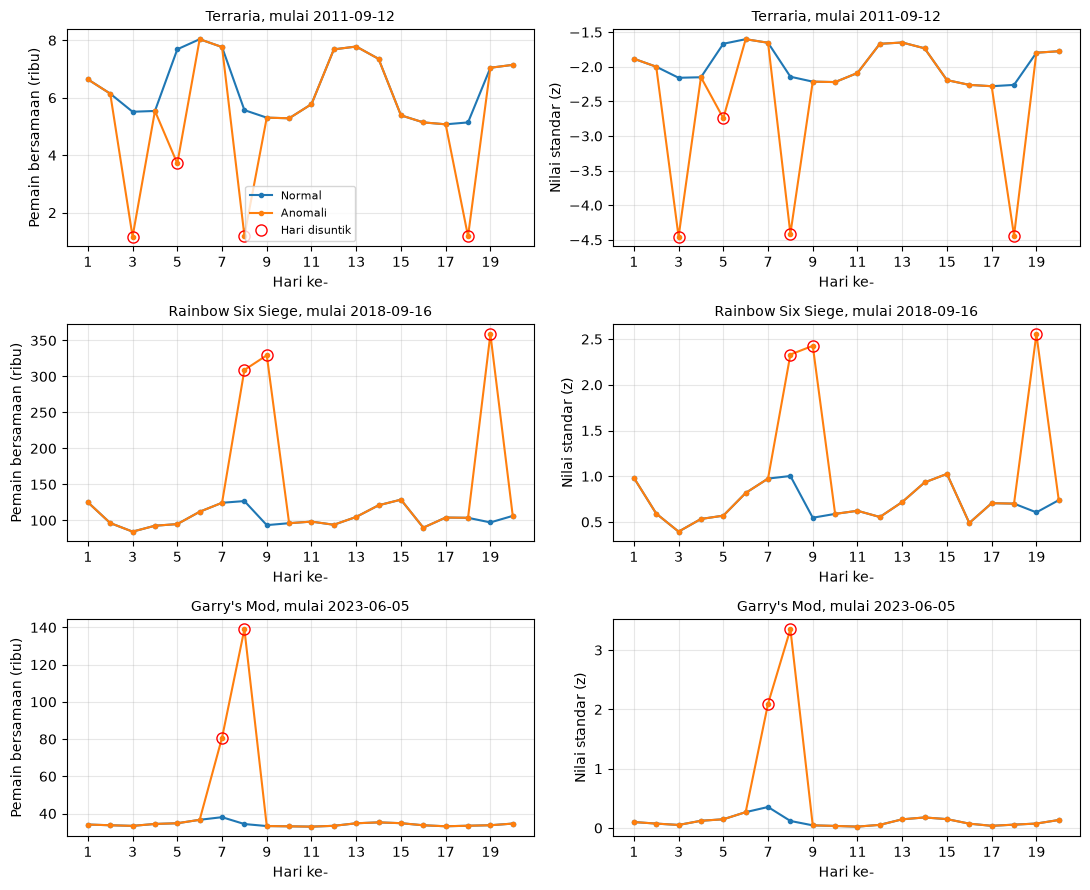

In [9]:
rng2 = np.random.default_rng(SEED + 1)
chosen = []
for gi in rng2.choice(len(GAMES), size=3, replace=False):
    chosen.append(rng2.choice(np.where((game_id == gi) & (~bump))[0]))

fig, axes = plt.subplots(3, 2, figsize=(11, 9))
x = np.arange(1, SEG_LEN + 1)
for r, i in enumerate(chosen):
    for c, (a, b, unit) in enumerate([(seg_raw[i] / 1000, anom_raw[i] / 1000, 'Pemain bersamaan (ribu)'),
                                       (z_norm[i], z_anom[i], 'Nilai standar (z)')]):
        ax = axes[r, c]
        ax.plot(x, a, 'o-', ms=3, label='Normal'); ax.plot(x, b, 'o-', ms=3, label='Anomali')
        ax.plot(x[mask[i]], b[mask[i]], 'o', color='red', ms=8, mfc='none', label='Hari disuntik')
        ax.set_xticks(range(1, SEG_LEN + 1, 2)); ax.set_xlabel('Hari ke-'); ax.set_ylabel(unit); ax.grid(alpha=0.3)
        ax.set_title(f'{NAMES[GAMES[game_id[i]]]}, mulai {start_date[i]}', fontsize=10)
        if r == 0 and c == 0: ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG/'04_contoh_pasangan_segmen.png', dpi=150); plt.show()

## 2.6 Ringkasan data dan menyimpan hasil

Tabel ini merangkum jumlah segmen dan persentase segmen normal yang sudah memuat lonjakan asli per game. Segmen dan labelnya disimpan ke `data/processed/`.

In [10]:
summ = info.copy()
summ['jumlah_segmen'] = [int((game_id == gi).sum()) for gi in range(len(GAMES))]
summ['segmen_ada_lonjakan_asli'] = [int(bump[game_id == gi].sum()) for gi in range(len(GAMES))]
summ['persen_lonjakan_asli'] = (100 * summ['segmen_ada_lonjakan_asli'] / summ['jumlah_segmen']).round(1)
total = {'game': 'Total', 'jumlah_hari': summ.jumlah_hari.sum(), 'hari_hilang': summ.hari_hilang.sum(),
         'diisi_interpolasi': summ.diisi_interpolasi.sum(), 'tetap_kosong': summ.tetap_kosong.sum(),
         'jumlah_segmen': N, 'segmen_ada_lonjakan_asli': int(bump.sum()), 'persen_lonjakan_asli': round(100 * bump.mean(), 1)}
summ = pd.concat([summ, pd.DataFrame([total])], ignore_index=True)
summ.to_csv(RES/'ringkasan_data.csv', index=False)

np.savez_compressed(PROC/'segmen.npz', normal_raw=seg_raw, anomali_raw=anom_raw, normal_z=z_norm, anomali_z=z_anom,
                    mask_anomali=mask, faktor=factor, game_id=game_id, split=split, games=np.array(GAMES))
meta = pd.DataFrame({'id': np.arange(N), 'game': [GAMES[i] for i in game_id], 'tanggal_mulai': start_date, 'split': split,
                     'hari_diisi_interpolasi': n_filled, 'ada_lonjakan_asli': bump, 'jumlah_titik_anomali': k_anom})
meta.to_csv(PROC/'segmen_meta.csv', index=False)
summ

,game,mulai,akhir,jumlah_hari,hari_hilang,diisi_interpolasi,tetap_kosong,median_pemain,jumlah_segmen,segmen_ada_lonjakan_asli,persen_lonjakan_asli
0,Dark Souls 3,2016-04-12,2025-06-20,3357,0,0,0,9546.0,167,17,10.2
1,Euro Truck Simulator 2,2013-01-01,2025-06-20,4554,110,1,109,29242.0,220,18,8.2
2,Garry's Mod,2012-01-01,2025-06-20,4920,25,4,21,35501.0,244,17,7.0
3,Rainbow Six Siege,2015-12-01,2025-06-20,3490,0,0,0,71573.0,174,9,5.2
4,Stardew Valley,2016-02-26,2025-06-20,3403,0,0,0,27131.0,170,13,7.6
5,Terraria,2011-05-15,2025-06-20,5151,52,1,51,26767.0,254,51,20.1
6,Total,NaN,NaN,24875,187,6,181,NaN,1229,125,10.2


# 3. Image Encoding

## 3.1 Empat belas encoding

Setiap segmen diubah menjadi matriks 20 x 20 dengan pustaka `pyts`: GADF, GASF, dan MTF dengan strategi uniform, quantile, dan normal, masing-masing dengan 2, 4, 5, dan 10 bin. Parameter lain dibiarkan default seperti di paper. Nilai GAF berada di rentang [-1, 1], sedangkan MTF di [0, 1].

Pengaturan pemanasan (encoding seluruh data sekali) dijalankan dulu supaya waktu kompilasi pyts tidak ikut terhitung.

In [11]:
X = np.vstack([z_norm, z_anom])                 # N segmen normal, lalu N segmen anomali
y = np.r_[np.zeros(N, int), np.ones(N, int)]    # 0 = normal, 1 = anomali

ENC = {'GADF': GramianAngularField(method='difference'), 'GASF': GramianAngularField(method='summation')}
for strat in ['uniform', 'quantile', 'normal']:
    for b in [2, 4, 5, 10]:
        ENC[f'MTF {strat.capitalize()} {b}'] = MarkovTransitionField(n_bins=b, strategy=strat)
VR = {n: (-1, 1) if n.startswith('GA') else (0, 1) for n in ENC}
ENC_NAMES = list(ENC)

for e in ENC.values():
    e.fit_transform(X)
MAT, t_encode = {}, {}
for name, e in ENC.items():
    t0 = time.perf_counter()
    MAT[name] = e.fit_transform(X)
    t_encode[name] = time.perf_counter() - t0
print(len(ENC), 'encoding, bentuk matriks:', MAT['GADF'].shape)

14 encoding, bentuk matriks: (2458, 20, 20)


## 3.2 Mengubah matriks menjadi gambar

Setiap nilai matriks dipetakan ke warna dengan colormap `rainbow` (rendah ungu, tinggi merah), baris disusun dengan `origin='lower'`, lalu diperbesar menjadi 150 x 150 piksel dengan metode tetangga terdekat, sehingga satu nilai matriks tetap menjadi satu warna. Gambar tidak disimpan ke disk karena ukurannya besar, dan dibuat ulang dari matriks setiap kali dibutuhkan. Di sini waktu konversinya dicatat.

In [12]:
cmap = plt.get_cmap('rainbow')
pix = (np.arange(IMG) * SEG_LEN) // IMG

def to_image(mats_, vmin, vmax):
    scaled = np.clip((mats_ - vmin) / (vmax - vmin), 0, 1)
    rgb = (cmap(scaled)[..., :3] * 255).astype(np.uint8)[:, ::-1]
    return rgb[:, pix][:, :, pix]

t_image = {}
for name in ENC:
    t0 = time.perf_counter()
    for s in range(0, len(X), 500):
        _ = to_image(MAT[name][s:s+500], *VR[name])
    t_image[name] = time.perf_counter() - t0

waktu_enc = pd.DataFrame({'encoding': ENC_NAMES, 'matriks_detik': [t_encode[n] for n in ENC_NAMES],
                          'gambar_detik': [t_image[n] for n in ENC_NAMES]})
waktu_enc['total_detik'] = waktu_enc.matriks_detik + waktu_enc.gambar_detik
if LATIH_ULANG:
    waktu_enc.round(3).to_csv(RES/'waktu_encoding.csv', index=False)
print(f'Waktu run ini: matriks {waktu_enc.matriks_detik.sum():.3f} s dan gambar {waktu_enc.gambar_detik.sum():.2f} s untuk 14 encoding')

Waktu run ini: matriks 0.046 s dan gambar 2.38 s untuk 14 encoding


## 3.3 Statistik matriks: Δmean, ΔSD, dan Δcount

Untuk setiap matriks dihitung rata-rata (mean), simpangan baku (SD), dan jumlah nilai unik (count), seperti di paper. Nilai ini dirata-ratakan untuk semua segmen normal dan semua segmen anomali, lalu diambil selisih absolutnya.

Cara membaca: makin besar selisihnya, makin berbeda gambar normal dan anomali secara statistik. Δmean GADF selalu 0 karena matriksnya antisimetris, dan Δmean MTF Quantile juga 0 karena setiap bin selalu terisi sama banyak. Count pada GAF hampir selalu mendekati batas maksimum karena jumlah pemain harian hampir tidak pernah sama dua kali.

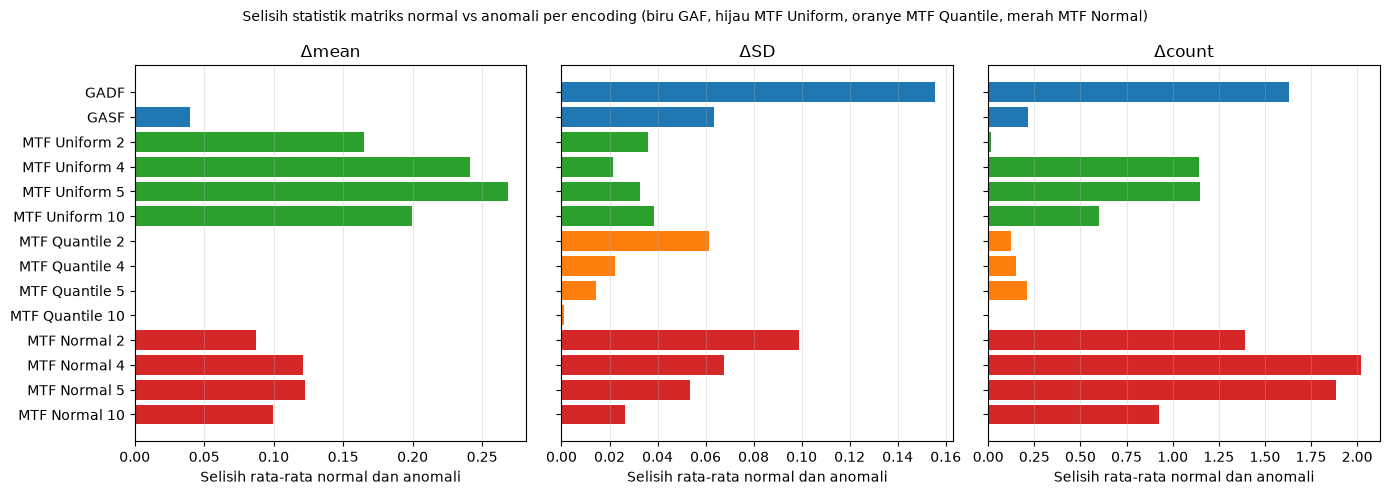

,encoding,delta_mean,delta_sd,delta_count
0,GADF,0.000,0.155,1.632
1,GASF,0.040,0.063,0.217
2,MTF Uniform 2,0.165,0.036,0.015
3,MTF Uniform 4,0.241,0.022,1.141
4,MTF Uniform 5,0.268,0.033,1.149
5,MTF Uniform 10,0.199,0.038,0.601
6,MTF Quantile 2,0.000,0.061,0.124
7,MTF Quantile 4,0.000,0.022,0.149
8,MTF Quantile 5,0.000,0.014,0.211
9,MTF Quantile 10,0.000,0.001,0.006


In [13]:
def matrix_stats(M):
    flat = M.reshape(len(M), -1)
    return flat.mean(axis=1), flat.std(axis=1), np.array([len(np.unique(r)) for r in flat])

rows = []
for name in ENC:
    m, s, c = matrix_stats(MAT[name])
    rows.append({'encoding': name, 'mean_normal': m[:N].mean(), 'mean_anomali': m[N:].mean(),
                 'sd_normal': s[:N].mean(), 'sd_anomali': s[N:].mean(),
                 'count_normal': c[:N].mean(), 'count_anomali': c[N:].mean()})
stat = pd.DataFrame(rows)
stat['delta_mean'] = (stat.mean_normal - stat.mean_anomali).abs()
stat['delta_sd'] = (stat.sd_normal - stat.sd_anomali).abs()
stat['delta_count'] = (stat.count_normal - stat.count_anomali).abs()
stat.round(3).to_csv(RES/'delta_per_encoding.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
colors = ['tab:blue'] * 2 + ['tab:green'] * 4 + ['tab:orange'] * 4 + ['tab:red'] * 4
for ax, col, ttl in zip(axes, ['delta_mean', 'delta_sd', 'delta_count'], ['Δmean', 'ΔSD', 'Δcount']):
    ax.barh(stat.encoding, stat[col], color=colors)
    ax.set_title(ttl); ax.set_xlabel('Selisih rata-rata normal dan anomali'); ax.grid(alpha=0.3, axis='x')
axes[0].invert_yaxis()
fig.suptitle('Selisih statistik matriks normal vs anomali per encoding (biru GAF, hijau MTF Uniform, oranye MTF Quantile, merah MTF Normal)', fontsize=10)
fig.tight_layout(); fig.savefig(FIG/'07_delta_per_encoding.png', dpi=150); plt.show()
stat[['encoding', 'delta_mean', 'delta_sd', 'delta_count']].round(3)

## 3.4 Gambar normal dan anomali berdampingan

Tiga segmen contoh (sama dengan contoh di 2.5). Atas: deret waktu terstandar. Tengah: gambar dari segmen normal. Bawah: gambar dari segmen anomali. Lima encoding mewakili setiap keluarga.

Cara membaca: pada GADF dan GASF, setiap hari yang disuntik muncul sebagai garis yang memotong gambar secara horizontal dan vertikal. Pada MTF Uniform warna dominannya berubah. Pada MTF Quantile, gambar normal dan anomali hampir sama, karena strategi ini hanya melihat urutan nilai dalam segmen, bukan besarnya.

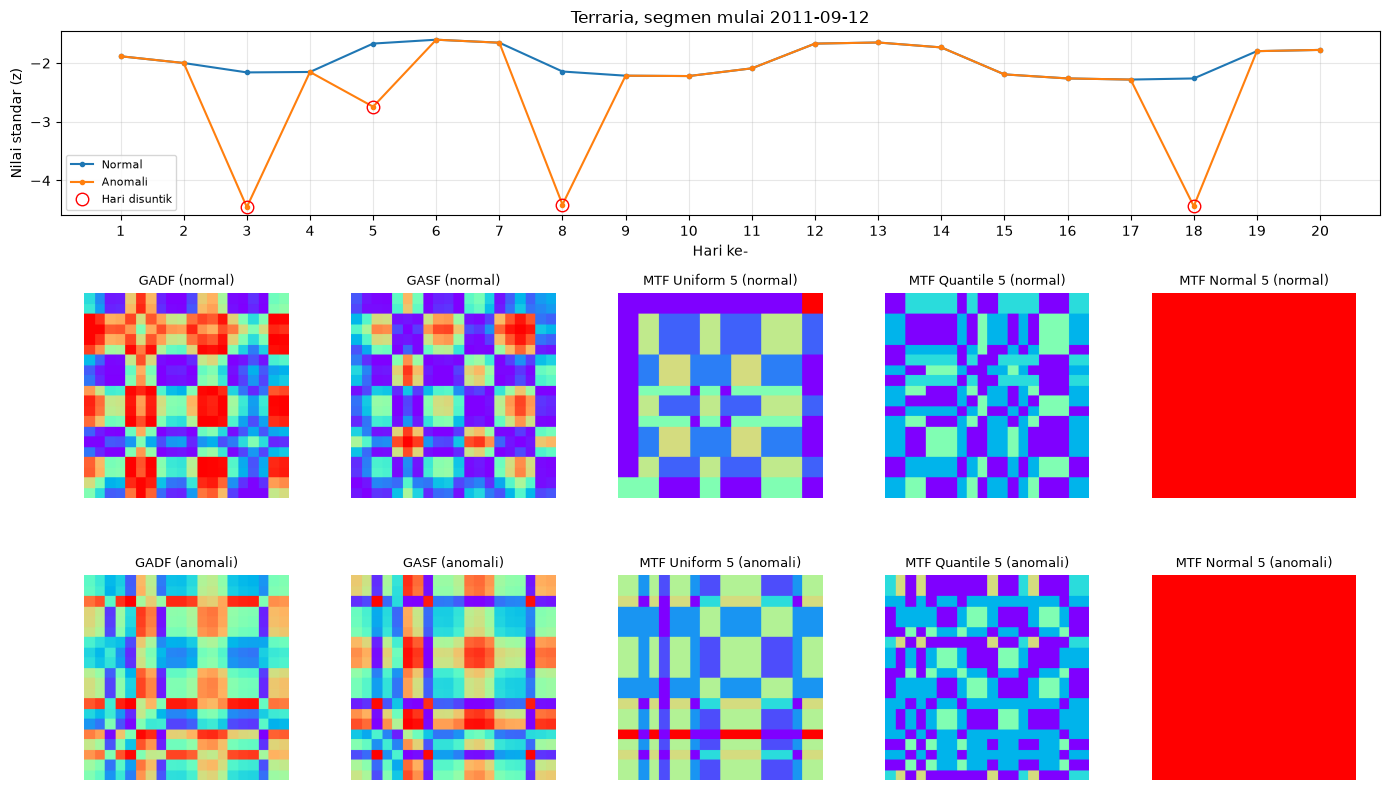

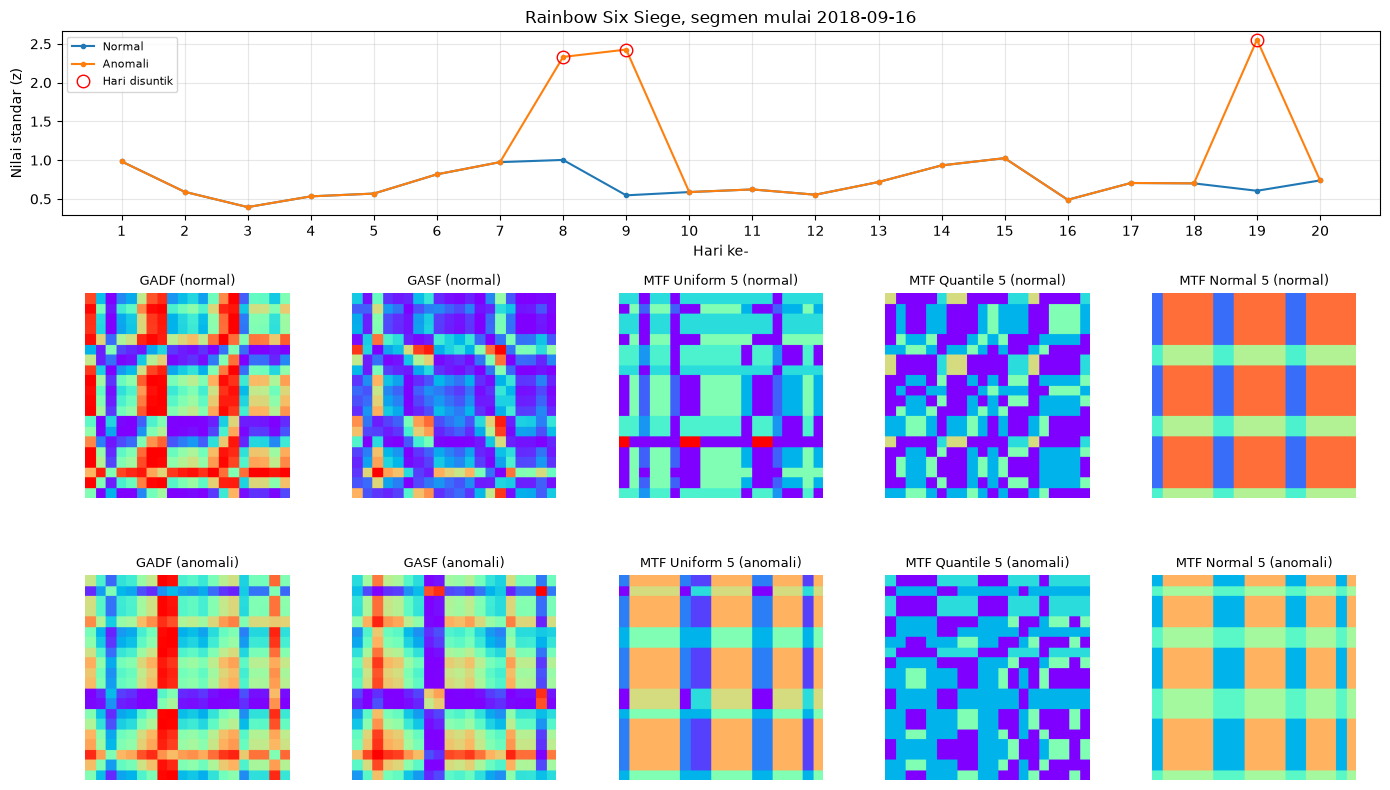

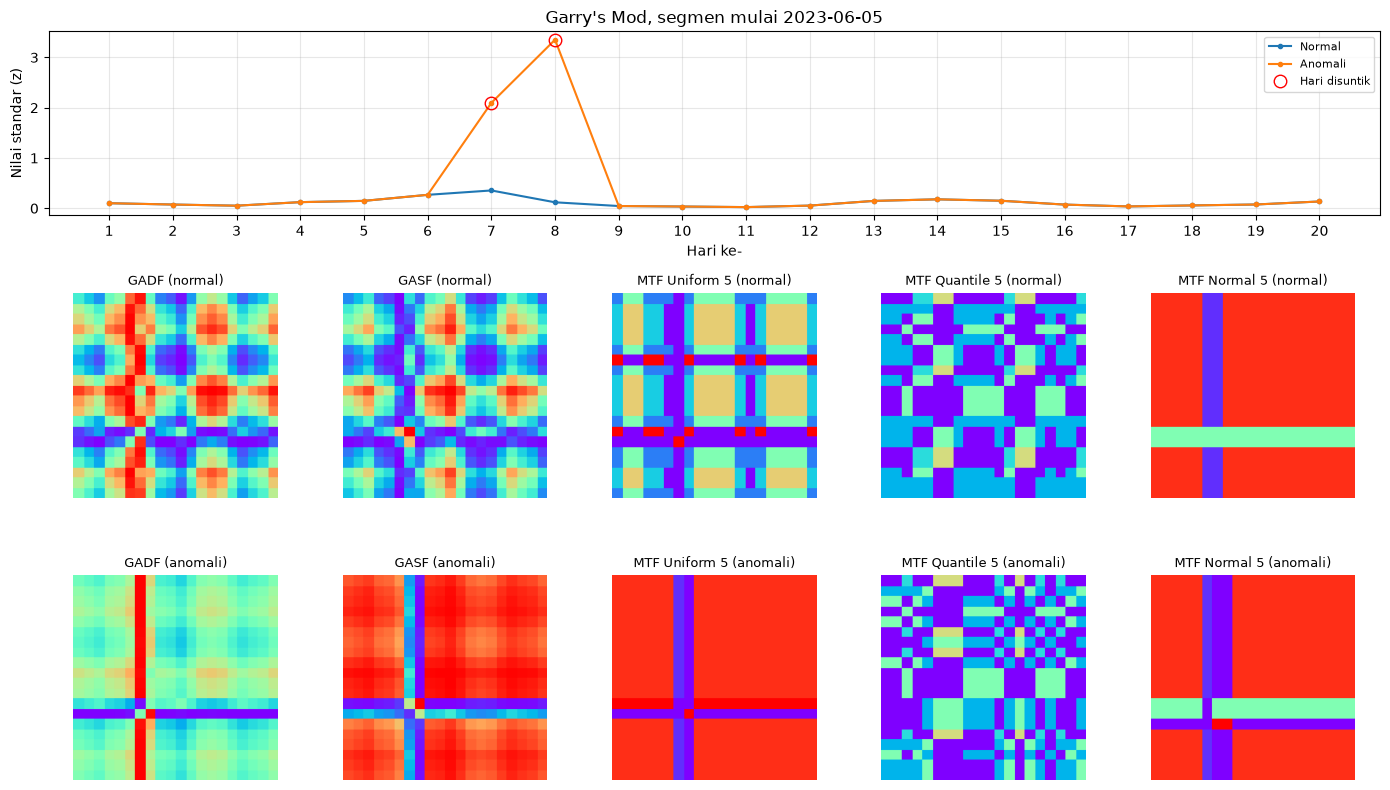

In [14]:
def image_of(name, i, anomali):
    return to_image(MAT[name][[i + N * anomali]], *VR[name])[0]

REP = ['GADF', 'GASF', 'MTF Uniform 5', 'MTF Quantile 5', 'MTF Normal 5']
for k, i in enumerate(chosen, 1):
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(3, 5, height_ratios=[0.9, 1, 1])
    ax = fig.add_subplot(gs[0, :])
    ax.plot(x, z_norm[i], 'o-', ms=3, label='Normal'); ax.plot(x, z_anom[i], 'o-', ms=3, label='Anomali')
    ax.plot(x[mask[i]], z_anom[i][mask[i]], 'o', color='red', ms=9, mfc='none', label='Hari disuntik')
    ax.set_xticks(x); ax.set_xlabel('Hari ke-'); ax.set_ylabel('Nilai standar (z)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_title(f'{NAMES[GAMES[game_id[i]]]}, segmen mulai {start_date[i]}')
    for c, name in enumerate(REP):
        for r, lab in enumerate(['normal', 'anomali']):
            a = fig.add_subplot(gs[r + 1, c]); a.imshow(image_of(name, i, r)); a.axis('off'); a.set_title(f'{name} ({lab})', fontsize=9)
    fig.tight_layout(); fig.savefig(FIG/f'05_pasangan_gambar_{k}.png', dpi=150); plt.show()

## 3.5 Mosaik 14 encoding untuk satu segmen

Satu segmen yang sama (Rainbow Six Siege) diubah dengan keempat belas encoding. Baris 1 dan 3 untuk segmen normal, baris 2 dan 4 untuk versi anomalinya.

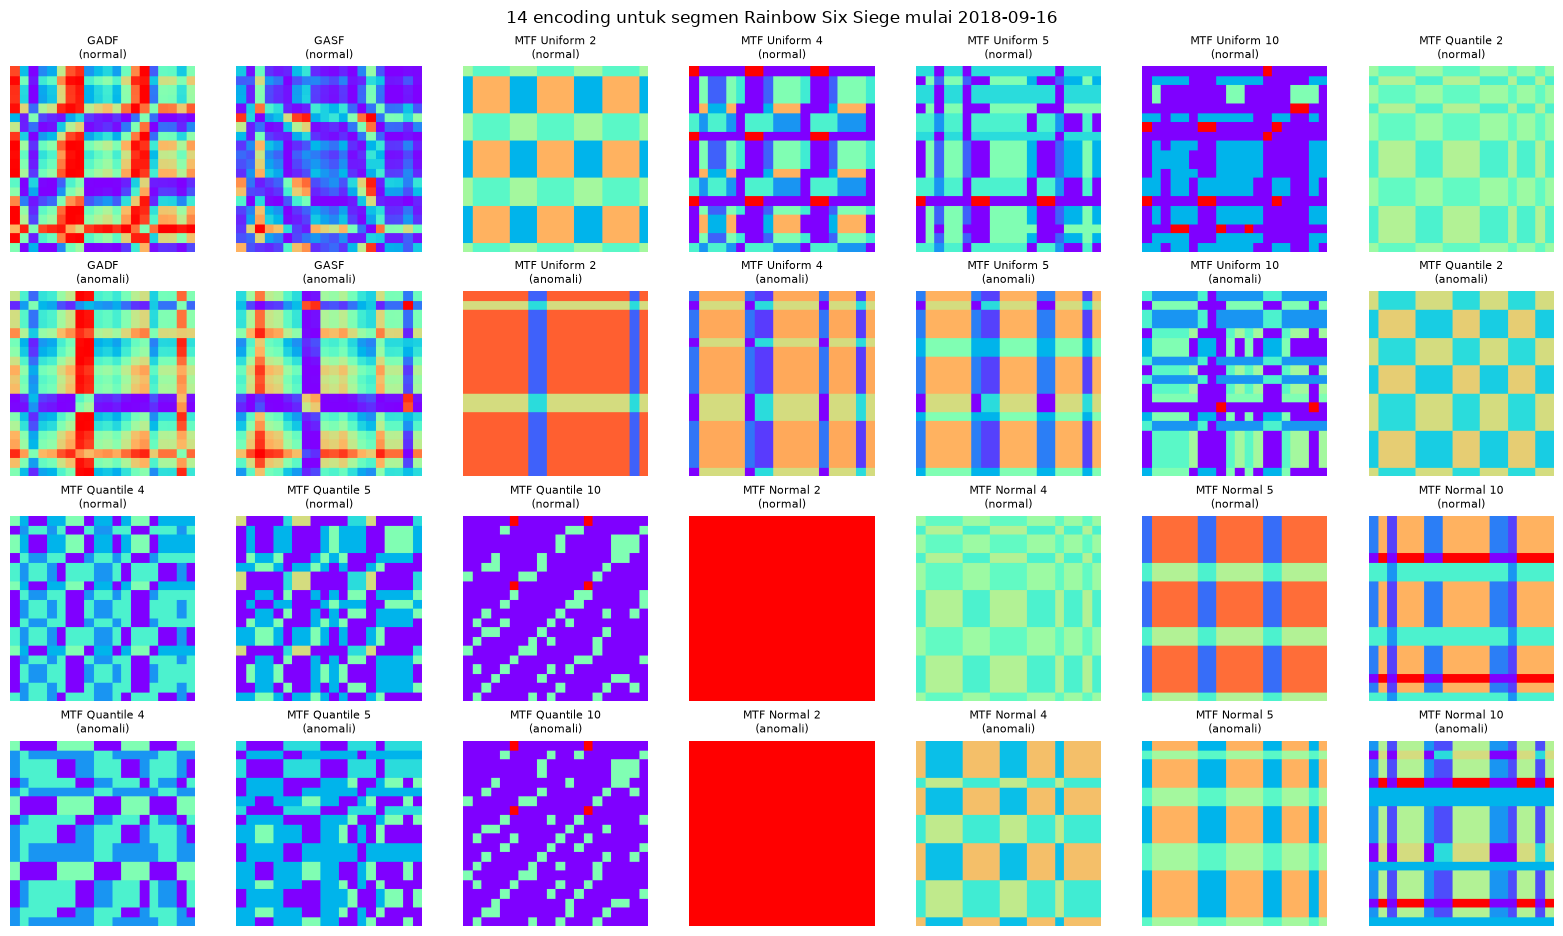

In [15]:
i = chosen[1]
fig, axes = plt.subplots(4, 7, figsize=(16, 9.5))
for j, name in enumerate(ENC_NAMES):
    r0 = 0 if j < 7 else 2
    for r, lab in enumerate(['normal', 'anomali']):
        a = axes[r0 + r, j % 7]; a.imshow(image_of(name, i, r)); a.axis('off'); a.set_title(f'{name}\n({lab})', fontsize=8)
fig.suptitle(f'14 encoding untuk segmen {NAMES[GAMES[game_id[i]]]} mulai {start_date[i]}')
fig.tight_layout(); fig.savefig(FIG/'06_mosaik_14_encoding.png', dpi=150); plt.show()

## 3.6 MTF Normal: kenapa tidak merah semua seperti di paper?

Di paper, semua gambar MTF Normal berwarna merah polos. Penyebabnya ada di cara `pyts` bekerja: strategi `normal` memakai batas bin tetap dari distribusi normal baku N(0, 1), dan batas ini langsung dipakai pada data apa adanya. Kalau semua nilai satu segmen jatuh ke bin yang sama, matriksnya hanya berisi angka 1, sehingga gambarnya merah polos. Pada data tegangan 4 sampai 5 V di paper, hal ini terjadi di semua segmen.

Data kita sudah distandarisasi sehingga nilainya berada di sekitar 0 dan tersebar di beberapa bin. Tabel berikut membandingkan persentase gambar seragam (satu warna) pada data terstandar dan pada data yang hanya diubah ke log10 tanpa standarisasi.

Cara membaca: tanpa standarisasi, 100% gambar seragam, sama seperti paper. Dengan standarisasi, gambar seragam masih muncul, tetapi jauh lebih sering pada segmen normal daripada segmen anomali. Perbedaan ini nanti dimanfaatkan CNN sebagai jalan pintas (lihat bagian 4.4).

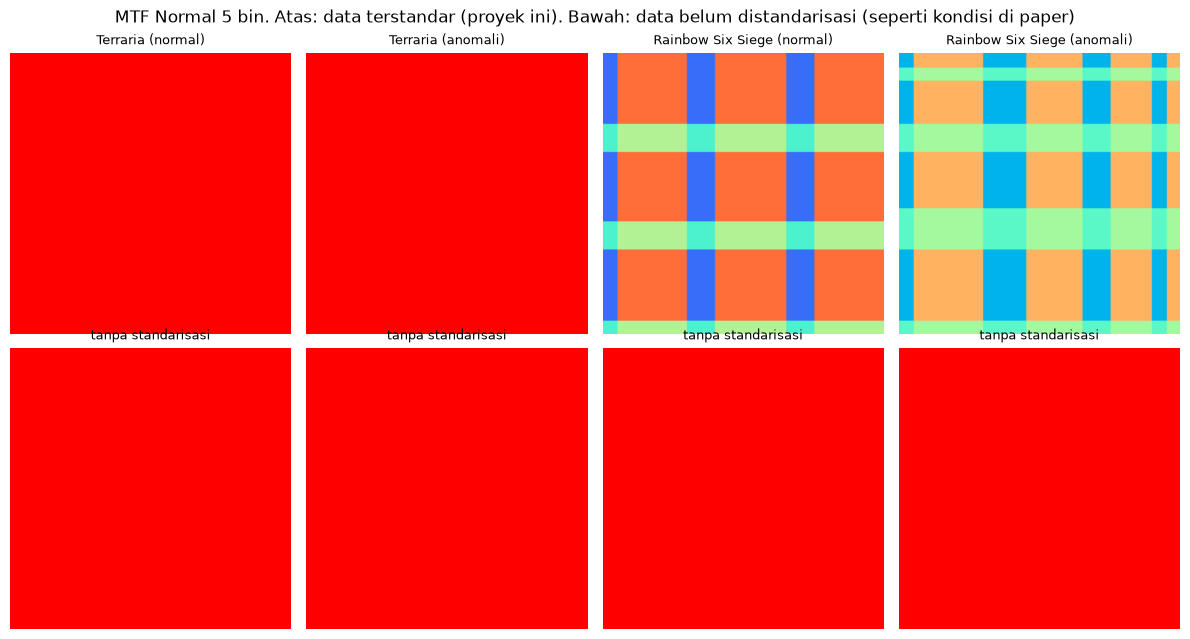

,n_bins,persen_gambar_seragam_normal_terstandar,persen_gambar_seragam_anomali_terstandar,persen_gambar_seragam_normal_mentah_log10,persen_gambar_seragam_anomali_mentah_log10
0,2,66.8,19.0,100.0,100.0
1,4,31.2,6.7,100.0,100.0
2,5,22.7,5.4,100.0,100.0
3,10,8.5,2.5,100.0,100.0


In [16]:
raw_log = np.log10(np.vstack([seg_raw, anom_raw]))
rows = []
for b in [2, 4, 5, 10]:
    r = {'n_bins': b}
    for lab, data in [('terstandar', X), ('mentah_log10', raw_log)]:
        M = MarkovTransitionField(n_bins=b, strategy='normal').fit_transform(data)
        const = M.reshape(len(M), -1).std(axis=1) == 0
        r[f'persen_gambar_seragam_normal_{lab}'] = 100 * const[:N].mean()
        r[f'persen_gambar_seragam_anomali_{lab}'] = 100 * const[N:].mean()
    rows.append(r)
mtfn = pd.DataFrame(rows).round(1)
mtfn.to_csv(RES/'mtf_normal_seragam.csv', index=False)

rows = []
for name in ENC_NAMES:
    if name.startswith('MTF'):
        const = MAT[name].reshape(len(X), -1).std(axis=1) == 0
        rows.append({'encoding': name, 'persen_seragam_normal': 100 * const[:N].mean(), 'persen_seragam_anomali': 100 * const[N:].mean()})
pd.DataFrame(rows).round(1).to_csv(RES/'gambar_seragam_mtf.csv', index=False)

M_raw5 = MarkovTransitionField(n_bins=5, strategy='normal').fit_transform(raw_log)
a_i, b_i = chosen[0], chosen[1]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for c, (idx_, lab) in enumerate([(a_i, 'normal'), (a_i + N, 'anomali'), (b_i, 'normal'), (b_i + N, 'anomali')]):
    axes[0, c].imshow(to_image(MAT['MTF Normal 5'][[idx_]], 0, 1)[0]); axes[0, c].set_title(f'{NAMES[GAMES[game_id[idx_ % N]]]} ({lab})', fontsize=9)
    axes[1, c].imshow(to_image(M_raw5[[idx_]], 0, 1)[0]); axes[1, c].set_title('tanpa standarisasi', fontsize=9)
    axes[0, c].axis('off'); axes[1, c].axis('off')
fig.suptitle('MTF Normal 5 bin. Atas: data terstandar (proyek ini). Bawah: data belum distandarisasi (seperti kondisi di paper)')
fig.tight_layout(); fig.savefig(FIG/'08_mtf_normal_standar_vs_mentah.png', dpi=150); plt.show()
mtfn

## 3.7 Menyimpan matriks

Matriks semua encoding disimpan dalam format float32. Bagian training dan Grad-CAM membaca matriks dari file ini (sama seperti saat hasil di paper dibuat), sehingga gambar yang masuk ke CNN identik.

In [17]:
np.savez_compressed(PROC/'matriks_encoding.npz', y=y, **{n.replace(' ', '_'): MAT[n].astype(np.float32) for n in ENC_NAMES})
mats = np.load(PROC/'matriks_encoding.npz')
KEYS = [n.replace(' ', '_') for n in ENC_NAMES]
print('Tersimpan:', (PROC/'matriks_encoding.npz').stat().st_size // 1024**2, 'MB')

Tersimpan: 6 MB


# 4. Training CNN

## 4.1 Arsitektur dan pengaturan

Arsitektur sama dengan paper: tiga blok Conv2D (16, 32, 64 filter, kernel 3 x 3, ReLU) yang masing-masing diikuti max pooling 2 x 2, lalu Dense 512 (ReLU) dan satu unit output. Optimizer RMSprop dengan learning rate 0,001 (parameter lain disamakan dengan default Keras, `alpha=0.9` dan `eps=1e-7`), loss binary cross-entropy, batch 20, dan 20 epoch. Sigmoid digabung ke fungsi loss (`BCEWithLogitsLoss`), yang secara matematis sama dengan sigmoid ditambah binary cross-entropy.

Pengaturan ini sama persis untuk ke-14 encoding, tanpa tuning khusus. Setiap model dibuat dengan seed yang sama, dan model setelah epoch ke-20 yang dievaluasi pada data test.

In [18]:
y_all = mats['y']
split_all = np.r_[meta.split.values, meta.split.values]
idx = {s: np.where(split_all == s)[0] for s in ['train', 'val', 'test']}
yt = y_all[idx['test']]

def block(i, o):
    return [nn.Conv2d(i, o, 3), nn.ReLU(), nn.MaxPool2d(2)]

def make_model():
    return nn.Sequential(*block(3, 16), *block(16, 32), *block(32, 64),
                         nn.Flatten(), nn.Linear(64 * 17 * 17, 512), nn.ReLU(), nn.Linear(512, 1))

def build_images(key):
    M = mats[key]
    vr = (-1, 1) if key.startswith('GA') else (0, 1)
    imgs = np.concatenate([to_image(M[s:s+500], *vr) for s in range(0, len(M), 500)])
    return torch.from_numpy(imgs).permute(0, 3, 1, 2).contiguous()

lossf = nn.BCEWithLogitsLoss()

def evaluate(model, Xs, ys):
    model.eval()
    logits = []
    with torch.no_grad():
        for s in range(0, len(Xs), 100):
            logits.append(model(Xs[s:s+100].float() / 255).squeeze(1))
    lo = torch.cat(logits)
    p = torch.sigmoid(lo).cpu().numpy()
    return lossf(lo, ys).item(), float(((p > 0.5) == ys.cpu().numpy().astype(bool)).mean()), p

print({s: len(v) for s, v in idx.items()}, 'gambar (separuh normal, separuh anomali)')

{'train': 1720, 'val': 368, 'test': 370} gambar (separuh normal, separuh anomali)


## 4.2 Melatih atau memuat model

Jika `LATIH_ULANG = True`, sel berikut melatih 14 CNN dan menyimpan bobot serta hasilnya. Jika `False`, hasil training dibaca dari `results/`, lalu bobot di `models/` dievaluasi ulang pada data test untuk memastikan bahwa model yang dimuat memang menghasilkan akurasi yang sama dengan tabel.

In [19]:
def train_encoding(key):
    Xa = build_images(key)
    Xtr, Xva, Xte = (Xa[idx[s]].to(DEV) for s in ['train', 'val', 'test'])
    ytr, yva, yte = (torch.tensor(y_all[idx[s]], dtype=torch.float32, device=DEV) for s in ['train', 'val', 'test'])
    torch.manual_seed(SEED)
    model = make_model().to(DEV)
    opt = torch.optim.RMSprop(model.parameters(), lr=LR, alpha=0.9, eps=1e-7)
    g = torch.Generator().manual_seed(SEED)
    hist = []
    t0 = time.perf_counter()
    for ep in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g)
        sl = sc = 0.0
        for s in range(0, len(Xtr), BATCH):
            ib = perm[s:s+BATCH].to(DEV)
            lo = model(Xtr[ib].float() / 255).squeeze(1)
            loss = lossf(lo, ytr[ib])
            opt.zero_grad(); loss.backward(); opt.step()
            sl += loss.item() * len(ib); sc += ((lo > 0) == (ytr[ib] > 0.5)).sum().item()
        vl, vacc, _ = evaluate(model, Xva, yva)
        hist.append(dict(epoch=ep, train_loss=sl / len(Xtr), train_acc=sc / len(Xtr), val_loss=vl, val_acc=vacc))
    t_train = time.perf_counter() - t0
    _, tr_acc, _ = evaluate(model, Xtr, ytr)
    _, va_acc, _ = evaluate(model, Xva, yva)
    _, te_acc, p_te = evaluate(model, Xte, yte)
    pred = (p_te > 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    torch.save({k: v.cpu() for k, v in model.state_dict().items()}, MODELS/f'{key}.pt')
    res = dict(encoding=key.replace('_', ' '), train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc,
               precision=precision_score(yt, pred, zero_division=0), recall=recall_score(yt, pred, zero_division=0),
               f1=f1_score(yt, pred, zero_division=0), tn=tn, fp=fp, fn=fn, tp=tp, waktu_training_detik=t_train)
    return res, pd.DataFrame(hist).assign(encoding=key.replace('_', ' ')), p_te

if LATIH_ULANG:
    results, histories, probs = [], [], {}
    for key in KEYS:
        r, h, p = train_encoding(key)
        results.append(r); histories.append(h); probs[r['encoding']] = p
        print(f"{r['encoding']:16s} test {r['test_acc']*100:5.1f}%  waktu {r['waktu_training_detik']:.0f} s")
    res = pd.DataFrame(results)
    hist = pd.concat(histories, ignore_index=True)
    hist.round(4).to_csv(RES/'riwayat_training.csv', index=False)
    tab = res.copy()
    for c in ['train_acc', 'val_acc', 'test_acc']:
        tab[c] = (tab[c] * 100).round(1)
    for c in ['precision', 'recall', 'f1']:
        tab[c] = tab[c].round(3)
    tab['waktu_training_detik'] = tab.waktu_training_detik.round(1)
    tab.to_csv(RES/'akurasi_encoding.csv', index=False)
    ids = pd.DataFrame({'gambar_id': idx['test'], 'segmen_id': idx['test'] % N, 'kelas': yt})
    pd.concat([ids, pd.DataFrame({k: v.round(4) for k, v in probs.items()})], axis=1).to_csv(RES/'prediksi_test.csv', index=False)
else:
    hist = pd.read_csv(RES/'riwayat_training.csv')
    pt_saved = pd.read_csv(RES/'prediksi_test.csv')
    probs = {n: pt_saved[n].values for n in ENC_NAMES}
    tab_saved = pd.read_csv(RES/'akurasi_encoding.csv')
    cek = []
    for key in KEYS:
        model = make_model().to(DEV)
        model.load_state_dict(torch.load(MODELS/f'{key}.pt'))
        Xte = build_images(key)[idx['test']].to(DEV)
        _, te_acc, _ = evaluate(model, Xte, torch.tensor(yt, dtype=torch.float32, device=DEV))
        nm = key.replace('_', ' ')
        cek.append({'encoding': nm, 'akurasi_test_tabel': tab_saved.set_index('encoding').loc[nm, 'test_acc'],
                    'akurasi_test_dari_bobot': round(100 * te_acc, 1)})
    cek = pd.DataFrame(cek)
    print('Semua akurasi dari bobot sama dengan tabel:', bool((cek.akurasi_test_tabel == cek.akurasi_test_dari_bobot).all()))

tab = pd.read_csv(RES/'akurasi_encoding.csv')

Semua akurasi dari bobot sama dengan tabel: True


## 4.3 Tabel akurasi

Akurasi train, validasi, dan test (dalam persen), serta precision, recall, dan F1 di data test, dengan kelas anomali sebagai kelas positif (analog Tabel 9 paper).

Cara membaca: GADF dan GASF paling akurat (sekitar 97 sampai 98%), lalu MTF Uniform, MTF Normal, dan MTF Quantile paling lemah. Banyak encoding MTF punya akurasi train jauh di atas akurasi test, yang menandakan overfitting. Karena pengaturan CNN sengaja disamakan dengan paper, tidak ada regularisasi tambahan. Test set hanya 370 gambar dan training hanya dilakukan sekali, jadi selisih beberapa poin antar encoding sebaiknya tidak ditafsirkan berlebihan.

In [20]:
tab[['encoding', 'train_acc', 'val_acc', 'test_acc', 'precision', 'recall', 'f1']]

,encoding,train_acc,val_acc,test_acc,precision,recall,f1
0,GADF,100.0,97.3,97.8,0.973,0.984,0.978
1,GASF,100.0,97.6,97.3,0.973,0.973,0.973
2,MTF Uniform 2,97.1,84.2,82.2,0.829,0.811,0.820
3,MTF Uniform 4,99.6,89.4,85.7,0.827,0.903,0.863
4,MTF Uniform 5,99.9,92.1,92.7,0.939,0.914,0.926
5,MTF Uniform 10,100.0,91.6,90.8,0.927,0.886,0.906
6,MTF Quantile 2,80.1,67.9,64.6,0.665,0.589,0.625
7,MTF Quantile 4,96.1,70.4,70.8,0.723,0.676,0.698
8,MTF Quantile 5,97.3,70.4,64.6,0.650,0.632,0.641
9,MTF Quantile 10,98.5,57.1,56.5,0.564,0.573,0.568


## 4.4 Kurva training dan confusion matrix

Kurva akurasi dan loss per epoch untuk tiap encoding (biru train, oranye validasi). Pada encoding yang overfitting, kurva train terus naik sementara kurva validasi mendatar sejak beberapa epoch awal.

Confusion matrix membandingkan encoding terbaik dan terburuk. Kedua panel memakai skala warna yang sama.

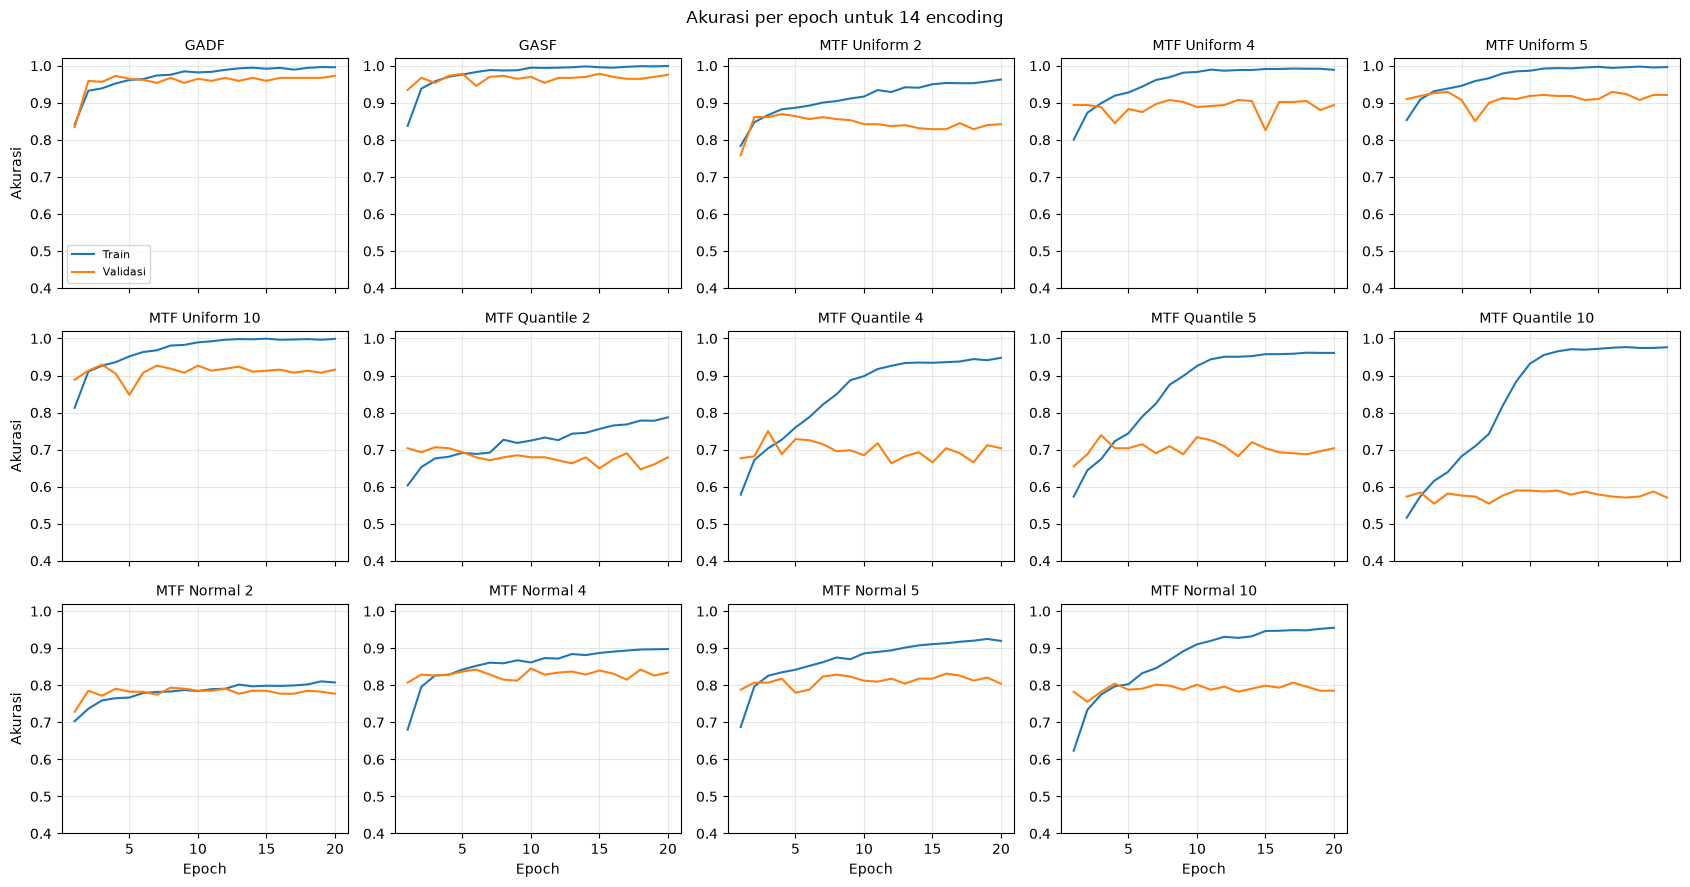

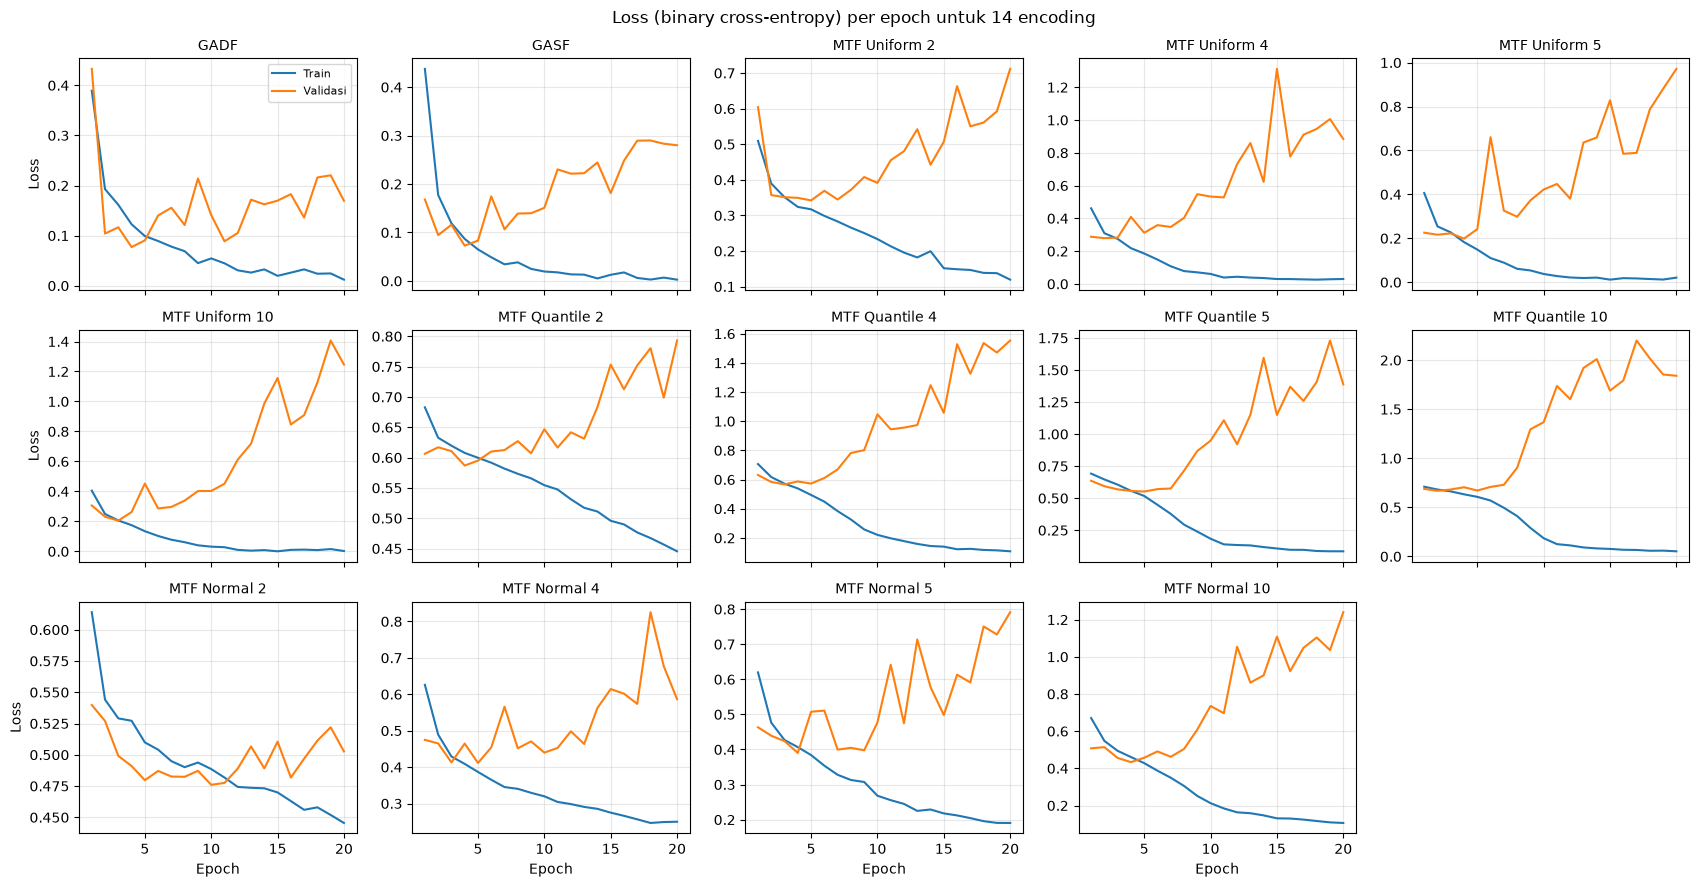

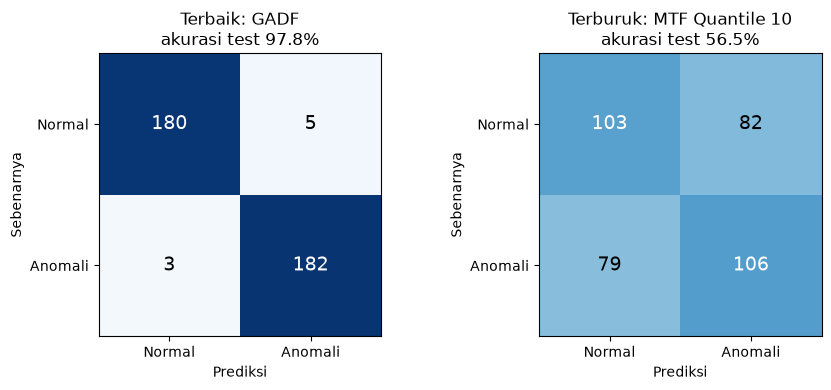

In [21]:
def curve_grid(cols_pair, ylabel, fname, title, ylim=None):
    fig, axes = plt.subplots(3, 5, figsize=(17, 9), sharex=True)
    for ax, nm in zip(axes.ravel(), ENC_NAMES):
        h = hist[hist.encoding == nm]
        ax.plot(h.epoch, h[cols_pair[0]], label='Train'); ax.plot(h.epoch, h[cols_pair[1]], label='Validasi')
        ax.set_title(nm, fontsize=10); ax.grid(alpha=0.3)
        if ylim: ax.set_ylim(*ylim)
    for ax in axes.ravel()[len(ENC_NAMES):]:
        ax.axis('off')
    for ax in axes[-1]: ax.set_xlabel('Epoch')
    for ax in axes[:, 0]: ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG/fname, dpi=150); plt.show()

curve_grid(['train_acc', 'val_acc'], 'Akurasi', '09_kurva_akurasi.png', 'Akurasi per epoch untuk 14 encoding', ylim=(0.4, 1.02))
curve_grid(['train_loss', 'val_loss'], 'Loss', '10_kurva_loss.png', 'Loss (binary cross-entropy) per epoch untuk 14 encoding')

order = tab.sort_values(['test_acc', 'f1'], ascending=[False, False])
best, worst = order.iloc[0], order.iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, r, lab in zip(axes, [best, worst], ['Terbaik', 'Terburuk']):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.sum(axis=1).max())
    for a in range(2):
        for b in range(2):
            ax.text(b, a, cm[a, b], ha='center', va='center', fontsize=14, color='white' if cm[a, b] > cm.sum(axis=1).max() / 2 else 'black')
    ax.set_xticks([0, 1], ['Normal', 'Anomali']); ax.set_yticks([0, 1], ['Normal', 'Anomali'])
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya')
    ax.set_title(f'{lab}: {r.encoding}\nakurasi test {r.test_acc:.1f}%')
fig.tight_layout(); fig.savefig(FIG/'11_confusion_matrix.png', dpi=150); plt.show()

## 4.5 MTF Normal dan gambar seragam

Bagian 3.6 menunjukkan bahwa gambar MTF Normal yang seragam lebih sering berasal dari segmen normal. Tabel berikut memisahkan akurasi test antara gambar seragam dan tidak seragam. Kolom batas atas adalah akurasi tertinggi yang mungkin dicapai jika CNN sempurna pada gambar tidak seragam tetapi hanya bisa menebak kelas terbanyak untuk gambar seragam.

Cara membaca: akurasi pada gambar seragam sama dengan proporsi segmen normal di antara gambar seragam (misalnya 120 dari 149 = 80,5% untuk 2 bin). Artinya CNN menebak "normal" untuk setiap gambar merah polos. Sisa akurasinya berasal dari pola pada gambar yang tidak seragam.

In [22]:
rows = []
te_idx = idx['test']
for b in [2, 4, 5, 10]:
    key = f'MTF_Normal_{b}'; nm = key.replace('_', ' ')
    uni = mats[key][te_idx].reshape(len(te_idx), -1).std(axis=1) == 0
    ok = (probs[nm] > 0.5).astype(int) == yt
    n_un, n_nu = uni.sum(), (~uni).sum()
    maj = max((yt[uni] == 0).sum(), (yt[uni] == 1).sum()) if n_un else 0
    rows.append({'encoding': nm,
                 'persen_seragam_segmen_normal': mtfn.set_index('n_bins').loc[b, 'persen_gambar_seragam_normal_terstandar'],
                 'persen_seragam_segmen_anomali': mtfn.set_index('n_bins').loc[b, 'persen_gambar_seragam_anomali_terstandar'],
                 'gambar_seragam_di_test': int(n_un), 'dari_itu_normal': int((yt[uni] == 0).sum()),
                 'akurasi_pada_seragam': round(100 * ok[uni].mean(), 1) if n_un else np.nan,
                 'akurasi_pada_tidak_seragam': round(100 * ok[~uni].mean(), 1),
                 'akurasi_test_total': round(100 * ok.mean(), 1),
                 'batas_atas_akurasi': round(100 * (n_nu + maj) / len(yt), 1)})
mtfn_acc = pd.DataFrame(rows)
mtfn_acc.to_csv(RES/'mtf_normal_akurasi.csv', index=False)
mtfn_acc

,encoding,persen_seragam_segmen_normal,persen_seragam_segmen_anomali,gambar_seragam_di_test,dari_itu_normal,akurasi_pada_seragam,akurasi_pada_tidak_seragam,akurasi_test_total,batas_atas_akurasi
0,MTF Normal 2,66.8,19.0,149,120,80.5,74.2,76.8,92.2
1,MTF Normal 4,31.2,6.7,59,51,86.4,79.4,80.5,97.8
2,MTF Normal 5,22.7,5.4,50,43,86.0,78.4,79.5,98.1
3,MTF Normal 10,8.5,2.5,18,14,77.8,75.3,75.4,98.9


## 4.6 Waktu komputasi

Waktu encoding (bagian 3) dan training per encoding, analog Tabel 14 paper. Training adalah bagian yang paling memakan waktu. Jika `LATIH_ULANG = False`, tabel ini dibaca dari `results/` (hasil saat model dilatih).

In [23]:
if LATIH_ULANG:
    w = waktu_enc.merge(tab[['encoding', 'waktu_training_detik']], on='encoding')
    w['total_detik'] = w.matriks_detik + w.gambar_detik + w.waktu_training_detik
    w['hemat_detik'] = w.gambar_detik + w.waktu_training_detik
    w['hemat_persen'] = 100 * w.hemat_detik / w.total_detik
    w.loc[len(w)] = ['Rata-rata'] + list(w.iloc[:, 1:].mean())
    w.round(3).to_csv(RES/'waktu_per_tahap.csv', index=False)
pd.read_csv(RES/'waktu_per_tahap.csv')[['encoding', 'matriks_detik', 'gambar_detik', 'waktu_training_detik']]

,encoding,matriks_detik,gambar_detik,waktu_training_detik
0,GADF,0.003,0.192,44.153
1,GASF,0.003,0.175,44.742
2,MTF Uniform 2,0.003,0.181,42.025
3,MTF Uniform 4,0.003,0.178,43.709
4,MTF Uniform 5,0.003,0.176,42.962
5,MTF Uniform 10,0.004,0.177,38.768
6,MTF Quantile 2,0.004,0.178,38.635
7,MTF Quantile 4,0.005,0.183,39.942
8,MTF Quantile 5,0.005,0.212,40.773
9,MTF Quantile 10,0.009,0.225,41.270


# 5. Korelasi Pearson

Setiap encoding (14 titik) punya tiga nilai Δ dari bagian 3.3 dan satu akurasi test dari bagian 4. Korelasi Pearson dihitung antara masing-masing Δ dan akurasi test, lalu dibandingkan dengan paper (Δmean 0,705, ΔSD 0,944, Δcount 0,455).

In [24]:
df = stat[['encoding', 'delta_mean', 'delta_sd', 'delta_count']].round(3).merge(tab[['encoding', 'test_acc']], on='encoding')
PAPER = {'delta_mean': 0.705, 'delta_sd': 0.944, 'delta_count': 0.455}
LABEL = {'delta_mean': 'Δmean', 'delta_sd': 'ΔSD', 'delta_count': 'Δcount'}
r_kita = {c: np.corrcoef(df[c], df.test_acc)[0, 1] for c in PAPER}
kor = pd.DataFrame({'fitur': [LABEL[c] for c in PAPER], 'r_kita': [round(r_kita[c], 3) for c in PAPER], 'r_paper': [PAPER[c] for c in PAPER]})
kor['peringkat_kita'] = kor.r_kita.rank(ascending=False).astype(int)
kor['peringkat_paper'] = kor.r_paper.rank(ascending=False).astype(int)
kor['selisih'] = (kor.r_kita - kor.r_paper).round(3)
kor.to_csv(RES/'korelasi_pearson.csv', index=False)
kor

,fitur,r_kita,r_paper,peringkat_kita,peringkat_paper,selisih
0,Δmean,0.496,0.705,2,2,-0.209
1,ΔSD,0.507,0.944,1,1,-0.437
2,Δcount,0.412,0.455,3,3,-0.043


Scatter berikut seperti Fig. 9 paper: tiap titik satu encoding, garis putus-putus adalah garis regresi linear, dan warna menunjukkan keluarga encoding.

Cara membaca dan pembahasan: urutan korelasinya sama dengan paper (ΔSD, lalu Δmean, lalu Δcount), tetapi ΔSD (0,507) dan Δmean (0,496) hampir seri, dan ΔSD jauh lebih lemah dari 0,944 di paper. Beberapa kemungkinan penyebabnya:

1. MTF Uniform (titik hijau) akurat walaupun ΔSD-nya kecil. Kekuatannya datang dari Δmean yang besar, sehingga titik hijau berada jauh di atas garis regresi ΔSD.
2. Di paper, keempat varian MTF Normal punya semua Δ bernilai nol dengan akurasi 50%. Kelompok titik ini kemungkinan ikut memperkuat korelasi. Di data kita MTF Normal tidak berada di titik itu.
3. Δmean bernilai nol untuk encoding terbaik (GADF) maupun terburuk (MTF Quantile), sehingga tidak bisa membedakan keduanya.
4. Δcount pada GAF hampir konstan karena jumlah nilai unik selalu mendekati batas maksimum. Δcount juga satu-satunya yang korelasinya mendekati paper.

Dengan hanya 14 titik, korelasi ini sangat dipengaruhi pengelompokan per keluarga encoding.

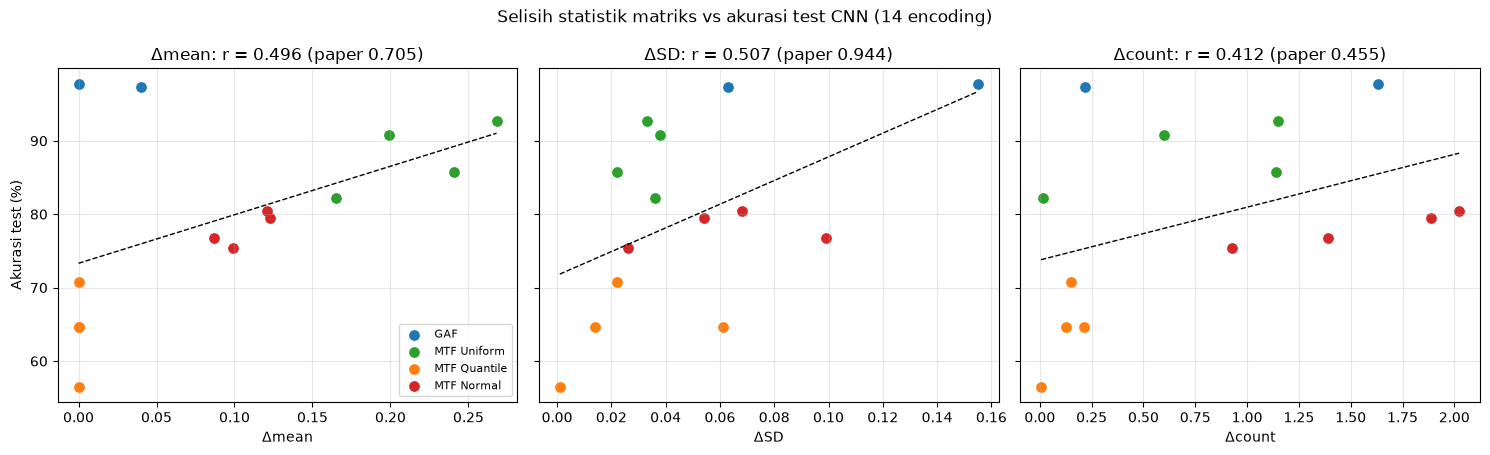

In [25]:
def family(n):
    return 'GAF' if n.startswith('GA') else ' '.join(n.split()[:2])
COL = {'GAF': 'tab:blue', 'MTF Uniform': 'tab:green', 'MTF Quantile': 'tab:orange', 'MTF Normal': 'tab:red'}
fam = df.encoding.map(family)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, c in zip(axes, PAPER):
    for f in COL:
        m = fam == f
        ax.scatter(df.loc[m, c], df.loc[m, 'test_acc'], color=COL[f], label=f, s=45)
    a, b = np.polyfit(df[c], df.test_acc, 1)
    xs = np.linspace(df[c].min(), df[c].max(), 50)
    ax.plot(xs, a * xs + b, 'k--', lw=1)
    ax.set_xlabel(LABEL[c]); ax.grid(alpha=0.3)
    ax.set_title(f'{LABEL[c]}: r = {r_kita[c]:.3f} (paper {PAPER[c]:.3f})')
axes[0].set_ylabel('Akurasi test (%)'); axes[0].legend(fontsize=8)
fig.suptitle('Selisih statistik matriks vs akurasi test CNN (14 encoding)')
fig.tight_layout(); fig.savefig(FIG/'12_korelasi_scatter.png', dpi=150); plt.show()

# 6. Grad-CAM

## 6.1 Cara kerja

Grad-CAM menunjukkan bagian gambar yang paling mendorong keluaran CNN ke arah "anomali". Caranya: ambil peta fitur dari lapisan konvolusi terakhir, hitung seberapa besar tiap peta mempengaruhi keluaran lewat gradien, jumlahkan peta-peta itu dengan bobot tersebut, lalu perbesar ke ukuran gambar.

Model yang dipakai adalah GADF karena akurasinya tertinggi. Pada GADF, piksel (i, j) mewakili hubungan hari ke-i dan hari ke-j. Peta panas dikembalikan ke matriks 20 x 20, lalu skor tiap hari adalah jumlah nilai pada baris dan kolom hari itu, dinormalisasi ke 0 sampai 1.

In [26]:
gmodel = make_model()
gmodel.load_state_dict(torch.load(MODELS/'GADF.pt'))
gmodel.eval()

def gradcam(xt):
    A = gmodel[:8](xt).detach().requires_grad_(True)
    logit = gmodel[8:](A)[0, 0]
    g, = torch.autograd.grad(logit, A)
    cam = F.relu((g.mean(dim=(2, 3), keepdim=True) * A).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG, IMG), mode='bilinear', align_corners=False)[0, 0].detach().numpy()
    return cam / cam.max() if cam.max() > 0 else cam, torch.sigmoid(logit).item()

def cam_to_days(cam):
    H = np.zeros((20, 20))
    for a in range(20):
        for b in range(20):
            H[a, b] = cam[np.ix_(np.where(19 - pix == a)[0], np.where(pix == b)[0])].mean()
    s = H.sum(axis=1) + H.sum(axis=0)
    return H, (s / s.max() if s.max() > 0 else s)

## 6.2 Contoh segmen anomali dari data test

Contoh dipilih dari segmen anomali di data test dengan seed tetap: dua segmen yang diklasifikasi benar (dari dua game berbeda) dan satu segmen yang salah diklasifikasi.

Cara membaca: kolom pertama gambar GADF, kolom kedua overlay Grad-CAM (gambar dibuat abu-abu supaya peta panas terlihat), lalu deret waktu dengan hari yang disuntik dilingkari merah, dan skor Grad-CAM per hari dengan batang merah untuk hari yang disuntik. Pada contoh yang benar, Grad-CAM menyorot garis silang yang bersesuaian dengan hari anomali. Pada contoh yang salah (Garry's Mod 2012), perhatian CNN tersebar, karena segmen itu sudah naik turun cukup besar secara alami sehingga satu lonjakan buatan tidak menonjol.

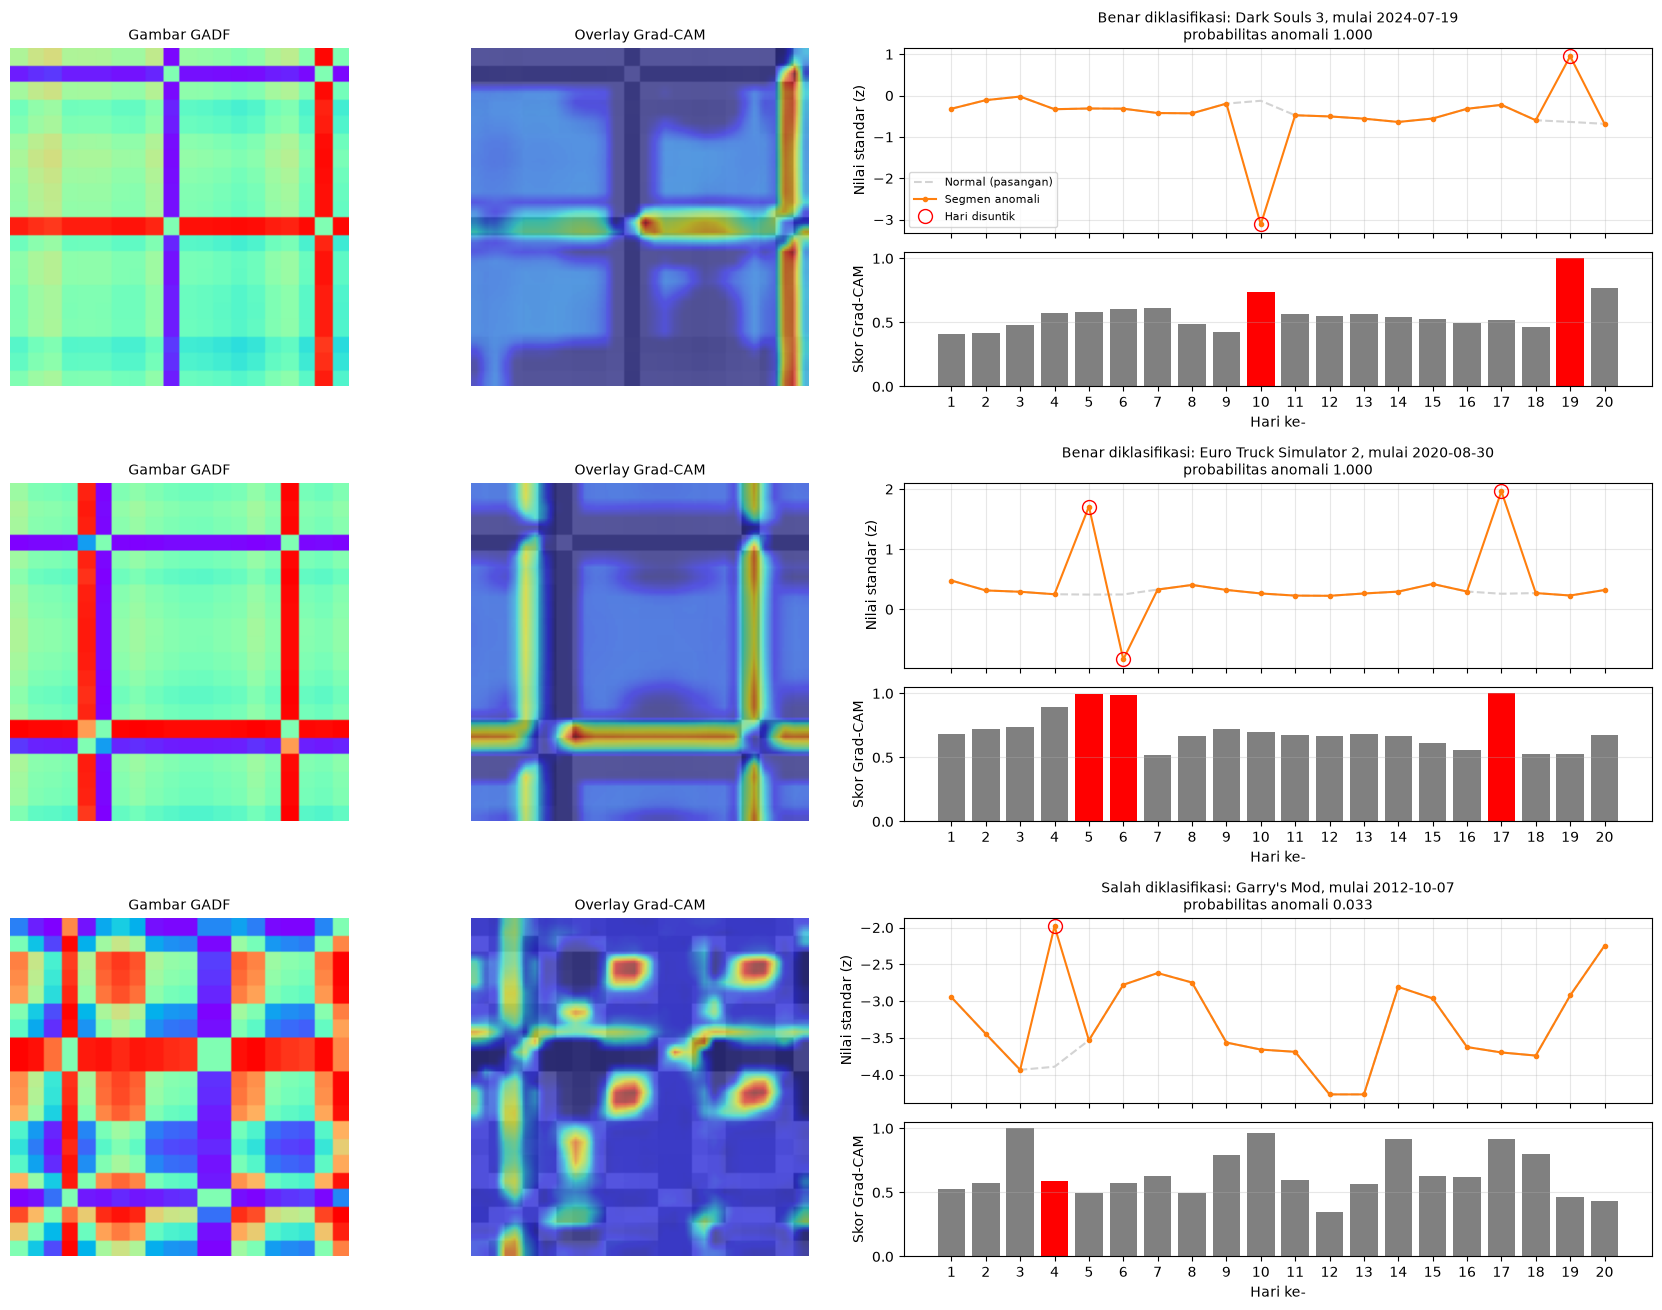

,jenis,gambar_id,segmen_id,game,tanggal_mulai,prob_anomali,hari_disuntik,hari_teratas_gradcam
0,Benar,1380,151,dark_souls_3,2024-07-19,1.000,"[10, 19]","[19, 20]"
1,Benar,1529,300,ets2,2020-08-30,1.000,"[5, 6, 17]","[5, 6, 17]"
2,Salah,1630,401,garrys_mod,2012-10-07,0.033,[4],[3]


In [27]:
pt = pd.read_csv(RES/'prediksi_test.csv')
an = pt[pt.kelas == 1].copy()
an['game'] = [meta.game[s] for s in an.segmen_id]
ok_an = an[an.GADF > 0.5].sample(frac=1, random_state=SEED)
picked, used = [], set()
for _, r in ok_an.iterrows():
    if r.game not in used:
        picked.append(('Benar', int(r.gambar_id))); used.add(r.game)
    if len(picked) == 2:
        break
bad = an[an.GADF <= 0.5]
if len(bad):
    picked.append(('Salah', int(bad.sample(1, random_state=SEED).gambar_id.iloc[0])))

gray = lambda im: np.repeat(im.mean(axis=2, keepdims=True), 3, axis=2).astype(np.uint8)
rows_info = []
fig = plt.figure(figsize=(17, 4.4 * len(picked)))
gs = fig.add_gridspec(len(picked), 3, width_ratios=[1, 1, 1.9])
for r, (kind, gid) in enumerate(picked):
    sid = gid - N
    im = to_image(mats['GADF'][[gid]], -1, 1)[0]
    xt = torch.from_numpy(im).permute(2, 0, 1)[None].float() / 255
    cam, prob = gradcam(xt)
    H, s = cam_to_days(cam)
    inj = np.where(mask[sid])[0]
    top = np.argsort(-s)[:len(inj)]
    title = f"{kind} diklasifikasi: {NAMES[meta.game[sid]]}, mulai {meta.tanggal_mulai[sid]}\nprobabilitas anomali {prob:.3f}"
    ax = fig.add_subplot(gs[r, 0]); ax.imshow(im); ax.axis('off'); ax.set_title('Gambar GADF', fontsize=10)
    ax = fig.add_subplot(gs[r, 1]); ax.imshow(gray(im)); ax.imshow(cam, cmap='jet', alpha=0.55, vmin=0, vmax=1); ax.axis('off')
    ax.set_title('Overlay Grad-CAM', fontsize=10)
    sub = gs[r, 2].subgridspec(2, 1, height_ratios=[1.1, 0.8], hspace=0.12)
    a1 = fig.add_subplot(sub[0]); a2 = fig.add_subplot(sub[1], sharex=a1)
    a1.plot(x, z_norm[sid], color='lightgray', ls='--', label='Normal (pasangan)')
    a1.plot(x, z_anom[sid], 'o-', ms=3, color='tab:orange', label='Segmen anomali')
    a1.plot(x[inj], z_anom[sid][inj], 'o', color='red', ms=10, mfc='none', label='Hari disuntik')
    a1.set_ylabel('Nilai standar (z)'); a1.grid(alpha=0.3); a1.set_title(title, fontsize=10); plt.setp(a1.get_xticklabels(), visible=False)
    if r == 0: a1.legend(fontsize=8)
    a2.bar(x, s, color=['red' if d in inj else 'gray' for d in range(20)])
    a2.set_xticks(x); a2.set_xlabel('Hari ke-'); a2.set_ylabel('Skor Grad-CAM'); a2.grid(alpha=0.3, axis='y')
    rows_info.append(dict(jenis=kind, gambar_id=gid, segmen_id=sid, game=meta.game[sid], tanggal_mulai=meta.tanggal_mulai[sid],
                          prob_anomali=round(prob, 3), hari_disuntik=[int(v) for v in inj + 1], hari_teratas_gradcam=sorted(int(v) for v in top + 1)))
fig.tight_layout(); fig.savefig(FIG/'13_gradcam_contoh.png', dpi=150); plt.show()
gc_info = pd.DataFrame(rows_info)
gc_info.to_csv(RES/'gradcam_contoh.csv', index=False)
gc_info

# 7. Ringkasan Insight

Tabel berikut mengumpulkan angka-angka utama dari bagian sebelumnya. Insight di bawahnya adalah rangkuman yang juga dipakai di paper.

In [28]:
ring = pd.DataFrame([
    ('Segmen normal (pasangan)', N),
    ('Segmen normal dengan lonjakan asli (%)', round(100 * bump.mean(), 1)),
    ('Segmen Terraria dengan lonjakan asli (%)', summ.set_index('game').loc['Terraria', 'persen_lonjakan_asli']),
    ('Pemain relatif hari Sabtu / Minggu / Rabu', f"{weekly.loc['Sab', 'Rata-rata semua game']:.3f} / {weekly.loc['Min', 'Rata-rata semua game']:.3f} / {weekly.loc['Rab', 'Rata-rata semua game']:.3f}"),
    ('Akurasi test GADF / GASF (%)', f"{tab.set_index('encoding').loc['GADF', 'test_acc']} / {tab.set_index('encoding').loc['GASF', 'test_acc']}"),
    ('Akurasi test MTF Uniform (%)', f"{tab[tab.encoding.str.startswith('MTF Uniform')].test_acc.min()} sampai {tab[tab.encoding.str.startswith('MTF Uniform')].test_acc.max()}"),
    ('Akurasi test MTF Normal (%)', f"{tab[tab.encoding.str.startswith('MTF Normal')].test_acc.min()} sampai {tab[tab.encoding.str.startswith('MTF Normal')].test_acc.max()}"),
    ('Akurasi test MTF Quantile (%)', f"{tab[tab.encoding.str.startswith('MTF Quantile')].test_acc.min()} sampai {tab[tab.encoding.str.startswith('MTF Quantile')].test_acc.max()}"),
    ('r ΔSD kita / paper', f"{kor.set_index('fitur').loc['ΔSD', 'r_kita']} / 0.944"),
], columns=['Hal', 'Nilai'])
ring

,Hal,Nilai
0,Segmen normal (pasangan),1229
1,Segmen normal dengan lonjakan asli (%),10.2
2,Segmen Terraria dengan lonjakan asli (%),20.1
3,Pemain relatif hari Sabtu / Minggu / Rabu,1.130 / 1.137 / 0.915
4,Akurasi test GADF / GASF (%),97.8 / 97.3
5,Akurasi test MTF Uniform (%),82.2 sampai 92.7
6,Akurasi test MTF Normal (%),75.4 sampai 80.5
7,Akurasi test MTF Quantile (%),56.5 sampai 70.8
8,r ΔSD kita / paper,0.507 / 0.944


1. **Akhir pekan adalah ritme dasar jumlah pemain.** Sabtu dan Minggu lebih ramai daripada hari kerja di keenam game, walaupun genre dan usia game-nya berbeda. Artinya segmen normal pun tidak datar: satu segmen 20 hari memuat hampir tiga siklus mingguan, dan metode deteksi harus bisa membedakan naik turun mingguan yang wajar dari perubahan yang tidak biasa.
2. **GAF unggul karena satu hari anomali menjadi pola yang mudah dilihat.** Satu hari yang berubah memengaruhi seluruh baris dan kolom hari itu, sehingga muncul garis silang di gambar. Grad-CAM menunjukkan bahwa CNN memang memperhatikan garis tersebut, dan posisinya bisa dipetakan kembali ke tanggal.
3. **MTF Quantile lemah karena hanya melihat urutan nilai.** Lonjakan dua kali lipat dan lima kali lipat bisa menghasilkan gambar yang sama, karena yang dihitung hanya urutan nilai dalam segmen, bukan besarnya.
4. **MTF Normal tidak gagal seperti di paper karena data distandarisasi, tetapi CNN sebagian memakai jalan pintas.** Gambar polos lebih sering berasal dari segmen normal, dan CNN belajar menebak "normal" untuk setiap gambar polos. Akurasi yang tinggi belum tentu berarti CNN memahami pola.
5. **Pemilihan encoding lewat statistik matriks kurang andal pada data ini.** Korelasi ΔSD jauh lebih lemah daripada di paper. Statistik matriks tetap berguna sebagai penyaring awal, tetapi hasilnya sebaiknya dipastikan dengan percobaan CNN.
6. **Data nyata sudah mengandung lonjakan yang mirip anomali.** Sekitar sepersepuluh segmen normal, dan seperlima segmen Terraria, sudah memuat lonjakan alami. Anomali buatan yang besarnya mirip variasi alami sulit dikenali, seperti pada contoh Garry's Mod yang salah diklasifikasi.

**Keterbatasan:** anomali yang dipakai adalah anomali buatan, sebagian besar encoding MTF mengalami overfitting, setiap encoding hanya dilatih sekali, dan data test hanya berisi 370 gambar.

In [29]:
print(f'Notebook selesai dalam {time.perf_counter() - T_MULAI:.0f} detik')

Notebook selesai dalam 15 detik
